In [16]:
# Necessary imports for this notebook
import os
import numpy as np
import pandas as pd
import datetime
import time
import random
# For plotting
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('darkgrid', {'axes.facecolor': '0.9'})


def generate_customer_profiles_table(n_customers, random_state=0):
    np.random.seed(random_state)
    customer_id_properties=[]
    # Generate customer properties from random distributions 
    for customer_id in range(n_customers):
        x_customer_id = np.random.uniform(0,100)
        y_customer_id = np.random.uniform(0,100)
        mean_amount = np.random.uniform(5,100) # Arbitrary (but sensible) value 
        std_amount = mean_amount/2 # Arbitrary (but sensible) value
        mean_nb_tx_per_day = np.random.uniform(0,4) # Arbitrary (but sensible) value 
        customer_id_properties.append([customer_id,
                                      x_customer_id, y_customer_id,
                                      mean_amount, std_amount,
                                      mean_nb_tx_per_day])
    customer_profiles_table = pd.DataFrame(customer_id_properties, columns=['CUSTOMER_ID',
                                                                      'x_customer_id', 'y_customer_id',
                                                                      'mean_amount', 'std_amount',
                                                                      'mean_nb_tx_per_day'])
    return customer_profiles_table


def generate_terminal_profiles_table(n_terminals, random_state=0):
    np.random.seed(random_state)
    terminal_id_properties=[]
    # Generate terminal properties from random distributions 
    for terminal_id in range(n_terminals):
        x_terminal_id = np.random.uniform(0,100)
        y_terminal_id = np.random.uniform(0,100)
        terminal_id_properties.append([terminal_id,
                                      x_terminal_id, y_terminal_id])
    terminal_profiles_table = pd.DataFrame(terminal_id_properties, columns=['TERMINAL_ID',
                                                                      'x_terminal_id', 'y_terminal_id'])
    return terminal_profiles_table


def get_list_terminals_within_radius(customer_profile, x_y_terminals, r):
    # Use numpy arrays in the following to speed up computations
    # Location (x,y) of customer as numpy array
    x_y_customer = customer_profile[['x_customer_id','y_customer_id']].values.astype(float)
    # Squared difference in coordinates between customer and terminal locations
    squared_diff_x_y = np.square(x_y_customer - x_y_terminals)
    # Sum along rows and compute suared root to get distance
    dist_x_y = np.sqrt(np.sum(squared_diff_x_y, axis=1))
    # Get the indices of terminals which are at a distance less than r
    available_terminals = list(np.where(dist_x_y<r)[0])
    # Return the list of terminal IDs
    return available_terminals
    

def generate_transactions_table(customer_profile, start_date = "2018-04-01", nb_days = 10):
    customer_transactions = []
    random.seed(int(customer_profile.CUSTOMER_ID))
    np.random.seed(int(customer_profile.CUSTOMER_ID))
    # For all days
    for day in range(nb_days):
        # Random number of transactions for that day 
        nb_tx = np.random.poisson(customer_profile.mean_nb_tx_per_day)
        # If nb_tx positive, let us generate transactions
        if nb_tx>0:
            for tx in range(nb_tx):
                # Time of transaction: Around noon, std 20000 seconds. This choice aims at simulating the fact that 
                # most transactions occur during the day.
                time_tx = int(np.random.normal(86400/2, 20000))
                # If transaction time between 0 and 86400, let us keep it, otherwise, let us discard it
                if (time_tx>0) and (time_tx<86400):
                    # Amount is drawn from a normal distribution  
                    amount = np.random.normal(customer_profile.mean_amount, customer_profile.std_amount)
                    # If amount negative, draw from a uniform distribution
                    if amount<0:
                        amount = np.random.uniform(0,customer_profile.mean_amount*2)
                    amount=np.round(amount,decimals=2)
                    if len(customer_profile.available_terminals)>0:
                        terminal_id = random.choice(customer_profile.available_terminals)
                        customer_transactions.append([time_tx+day*86400, day,
                                                      customer_profile.CUSTOMER_ID, 
                                                      terminal_id, amount])
    customer_transactions = pd.DataFrame(customer_transactions, columns=['TX_TIME_SECONDS', 'TX_TIME_DAYS', 'CUSTOMER_ID', 'TERMINAL_ID', 'TX_AMOUNT'])
    
    if len(customer_transactions)>0:
        customer_transactions['TX_DATETIME'] = pd.to_datetime(customer_transactions["TX_TIME_SECONDS"], unit='s', origin=start_date)
        customer_transactions=customer_transactions[['TX_DATETIME','CUSTOMER_ID', 'TERMINAL_ID', 'TX_AMOUNT','TX_TIME_SECONDS', 'TX_TIME_DAYS']]
    
    return customer_transactions 
    
def generate_dataset(n_customers=10000, n_terminals=1000000, nb_days=365, start_date="2018-04-01", r=5,
                      random_state_customers=0, random_state_terminals=1):
    start_time=time.time()
    customer_profiles_table = generate_customer_profiles_table(n_customers, random_state=random_state_customers)
    print("Time to generate customer profiles table: {0:.2}s".format(time.time()-start_time))
    start_time=time.time()
    terminal_profiles_table = generate_terminal_profiles_table(n_terminals, random_state=random_state_terminals)
    print("Time to generate terminal profiles table: {0:.2}s".format(time.time()-start_time))
    start_time=time.time()
    x_y_terminals = terminal_profiles_table[['x_terminal_id','y_terminal_id']].values.astype(float)
    customer_profiles_table['available_terminals'] = customer_profiles_table.apply(lambda x : get_list_terminals_within_radius(x, x_y_terminals=x_y_terminals, r=r), axis=1)
    # With Pandarallel
    #customer_profiles_table['available_terminals'] = customer_profiles_table.parallel_apply(lambda x : get_list_closest_terminals(x, x_y_terminals=x_y_terminals, r=r), axis=1)
    customer_profiles_table['nb_terminals']=customer_profiles_table.available_terminals.apply(len)
    print("Time to associate terminals to customers: {0:.2}s".format(time.time()-start_time))
    start_time=time.time()
    transactions_df=customer_profiles_table.groupby('CUSTOMER_ID').apply(lambda x : generate_transactions_table(x.iloc[0], nb_days=nb_days)).reset_index(drop=True)
    # With Pandarallel
    #transactions_df=customer_profiles_table.groupby('CUSTOMER_ID').parallel_apply(lambda x : generate_transactions_table(x.iloc[0], nb_days=nb_days)).reset_index(drop=True)
    print("Time to generate transactions: {0:.2}s".format(time.time()-start_time))
    # Sort transactions chronologically
    transactions_df=transactions_df.sort_values('TX_DATETIME')
    # Reset indices, starting from 0
    transactions_df.reset_index(inplace=True,drop=True)
    transactions_df.reset_index(inplace=True)
    # TRANSACTION_ID are the dataframe indices, starting from 0
    transactions_df.rename(columns = {'index':'TRANSACTION_ID'}, inplace = True)
    return (customer_profiles_table, terminal_profiles_table, transactions_df)


def add_frauds(customer_profiles_table, terminal_profiles_table, transactions_df):
    # By default, all transactions are genuine
    transactions_df['TX_FRAUD']=0
    transactions_df['TX_FRAUD_SCENARIO']=0
    # Scenario 1
    transactions_df.loc[transactions_df.TX_AMOUNT>220, 'TX_FRAUD']=1
    transactions_df.loc[transactions_df.TX_AMOUNT>220, 'TX_FRAUD_SCENARIO']=1
    nb_frauds_scenario_1=transactions_df.TX_FRAUD.sum()
    print("Number of frauds from scenario 1: "+str(nb_frauds_scenario_1))
    # Scenario 2
    for day in range(transactions_df.TX_TIME_DAYS.max()):
        compromised_terminals = terminal_profiles_table.TERMINAL_ID.sample(n=2, random_state=day)
        compromised_transactions=transactions_df[(transactions_df.TX_TIME_DAYS>=day) & 
                                                    (transactions_df.TX_TIME_DAYS<day+28) & 
                                                    (transactions_df.TERMINAL_ID.isin(compromised_terminals))]                 
        transactions_df.loc[compromised_transactions.index,'TX_FRAUD']=1
        transactions_df.loc[compromised_transactions.index,'TX_FRAUD_SCENARIO']=2
    nb_frauds_scenario_2=transactions_df.TX_FRAUD.sum()-nb_frauds_scenario_1
    print("Number of frauds from scenario 2: "+str(nb_frauds_scenario_2))
    
    # Scenario 3
    for day in range(transactions_df.TX_TIME_DAYS.max()):
        compromised_customers = customer_profiles_table.CUSTOMER_ID.sample(n=3, random_state=day).values
        compromised_transactions=transactions_df[(transactions_df.TX_TIME_DAYS>=day) & 
                                                    (transactions_df.TX_TIME_DAYS<day+14) & 
                                                    (transactions_df.CUSTOMER_ID.isin(compromised_customers))]
        nb_compromised_transactions=len(compromised_transactions)
        random.seed(day)
        index_fauds = random.sample(list(compromised_transactions.index.values),k=int(nb_compromised_transactions/3))
        transactions_df.loc[index_fauds,'TX_AMOUNT']=transactions_df.loc[index_fauds,'TX_AMOUNT']*5
        transactions_df.loc[index_fauds,'TX_FRAUD']=1
        transactions_df.loc[index_fauds,'TX_FRAUD_SCENARIO']=3              
    nb_frauds_scenario_3=transactions_df.TX_FRAUD.sum()-nb_frauds_scenario_2-nb_frauds_scenario_1
    print("Number of frauds from scenario 3: "+str(nb_frauds_scenario_3))
    
    return transactions_df                 


def get_stats(transactions_df):
    #Number of transactions per day
    nb_tx_per_day=transactions_df.groupby(['TX_TIME_DAYS'])['CUSTOMER_ID'].count()
    #Number of fraudulent transactions per day
    nb_fraud_per_day=transactions_df.groupby(['TX_TIME_DAYS'])['TX_FRAUD'].sum()
    #Number of fraudulent cards per day
    nb_fraudcard_per_day=transactions_df[transactions_df['TX_FRAUD']>0].groupby(['TX_TIME_DAYS']).CUSTOMER_ID.nunique()
    return (nb_tx_per_day,nb_fraud_per_day,nb_fraudcard_per_day)



In [17]:
N_RUNS = 1  # número de datasets a generar
DIR_OUTPUT = "./simulated-data/"

if not os.path.exists(DIR_OUTPUT):
    os.makedirs(DIR_OUTPUT)

for i in range(1, N_RUNS + 1):
    print(f"\n=== Iteración {i}/{N_RUNS} ===")
    
    # Usar una semilla distinta por iteración
    seed_customers = i * 100
    seed_terminals = i * 200
    
    # Generar dataset base con seeds variables
    (customer_profiles_table, terminal_profiles_table, transactions_df) = generate_dataset(
    n_customers = 80000, n_terminals = 10000, nb_days = 457, start_date = "2018-04-01", r = 7,
    random_state_customers=seed_customers, random_state_terminals=seed_terminals)

    # Agregar fraudes
    transactions_df = add_frauds(customer_profiles_table, terminal_profiles_table, transactions_df)

    # Concatenar días
    start_date = datetime.datetime.strptime("2018-04-01", "%Y-%m-%d")
    all_days = []
    for day in range(transactions_df.TX_TIME_DAYS.max() + 1):
        transactions_day = transactions_df[transactions_df.TX_TIME_DAYS == day].sort_values('TX_TIME_SECONDS')
        date = start_date + datetime.timedelta(days=day)
        transactions_day = transactions_day.assign(TX_DATE=date)
        all_days.append(transactions_day)

    transactions_all = pd.concat(all_days, ignore_index=True)

    # Guardar dataset con nombre único
    filename_output = f"transactions_all_run{i}.parquet"
    transactions_all.to_parquet(os.path.join(DIR_OUTPUT, filename_output), index=False)
    
    print(f"✅ Dataset {i} guardado en: {os.path.join(DIR_OUTPUT, filename_output)}")


=== Iteración 1/1 ===
Time to generate customer profiles table: 0.41s
Time to generate terminal profiles table: 0.028s
Time to associate terminals to customers: 1.3e+01s
Time to generate transactions: 1.9e+03s
Number of frauds from scenario 1: 40601
Number of frauds from scenario 2: 382805
Number of frauds from scenario 3: 11685
✅ Dataset 1 guardado en: ./simulated-data/transactions_all_run1.parquet


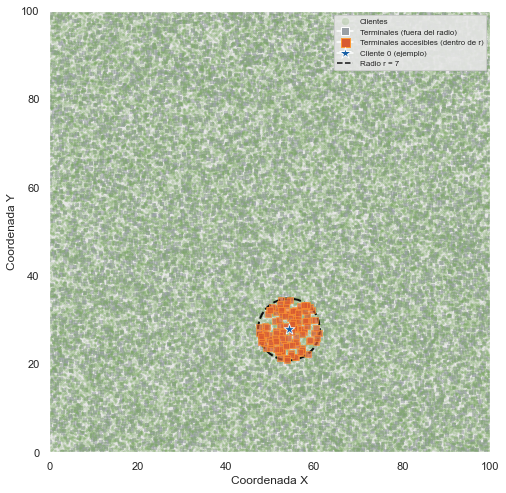

Cliente 0 en (54.3, 27.8) — 133 terminales dentro del radio r=7


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- Parámetros ---
RADIO = 7          
CLIENTE_EJEMPLO = 0  
SEED = 42          

# --- Datos (asumiendo tus dos DataFrames ya cargados) ---
# customer_profiles_table: CUSTOMER_ID, x_customer_id, y_customer_id, ...
# terminal_profiles_table: TERMINAL_ID, x_terminal_id, y_terminal_id

cx = customer_profiles_table["x_customer_id"].values
cy = customer_profiles_table["y_customer_id"].values
tx = terminal_profiles_table["x_terminal_id"].values
ty = terminal_profiles_table["y_terminal_id"].values

# --- Cliente de ejemplo y terminales dentro del radio ---
cliente = customer_profiles_table.loc[
    customer_profiles_table["CUSTOMER_ID"] == CLIENTE_EJEMPLO
].iloc[0]
x0, y0 = cliente["x_customer_id"], cliente["y_customer_id"]

dist = np.sqrt((tx - x0) ** 2 + (ty - y0) ** 2)
dentro = dist <= RADIO

# --- Figura ---
fig, ax = plt.subplots(figsize=(7, 7))

# Todas las terminales (fuera del radio): gris tenue
ax.scatter(tx[~dentro], ty[~dentro], s=14, c="#9aa0a6",
           marker="s", alpha=0.55, linewidths=0, zorder=2)

# Todos los clientes: puntos suaves
ax.scatter(cx, cy, s=6, c="#7AA860", alpha=0.25,
           linewidths=0, zorder=2
           )

# Terminales dentro del radio: resaltadas
ax.scatter(tx[dentro], ty[dentro], s=35, c="#D85A30", alpha=0.7,
           marker="s", edgecolors="#FF9933", linewidths=0.8, zorder=4
           )

# Círculo de radio r
circ = plt.Circle((x0, y0), RADIO, fill=False,
                  edgecolor="#0F0F0F", linestyle="--", linewidth=2, zorder=3)
ax.add_patch(circ)

# Cliente de ejemplo destacado
ax.scatter([x0], [y0], s=130, c="#185FA5", marker="*",
           edgecolors="white", linewidths=0.8, zorder=5)

# --- Estética ---
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_aspect("equal")
ax.set_xlabel("Coordenada X")
ax.set_ylabel("Coordenada Y")

ax.grid(True, linestyle=":", alpha=0.3)

leyenda = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#7AA860",
           markersize=8, label="Clientes", alpha=0.25),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#9aa0a6",
           markersize=8, label="Terminales (fuera del radio)"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#D85A30",
           markeredgecolor="#FF9933", markersize=9,
           label="Terminales accesibles (dentro de r)"),
    Line2D([0], [0], marker="*", color="w", markerfacecolor="#185FA5",
           markersize=13, label=f"Cliente {CLIENTE_EJEMPLO} (ejemplo)"),
    Line2D([0], [0], linestyle="--", color="#0F0F0F", label=f"Radio r = {RADIO}"),
]
ax.legend(handles=leyenda, loc="upper right", fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig("fig4_geografia_simulador.pdf", dpi=300, bbox_inches="tight")  # vectorial para LaTeX
plt.savefig("fig4_geografia_simulador.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Cliente {CLIENTE_EJEMPLO} en ({x0:.1f}, {y0:.1f}) — "
      f"{dentro.sum()} terminales dentro del radio r={RADIO}")

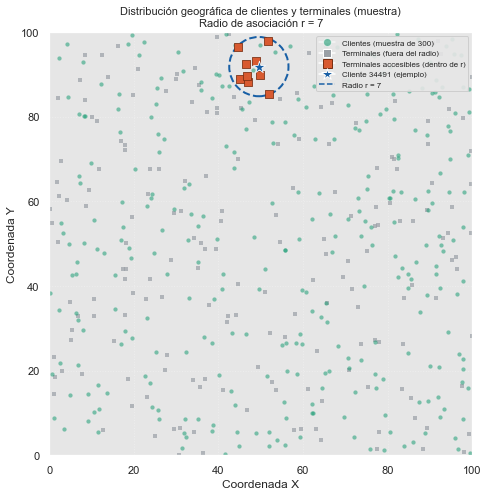

Cliente 34491 en (49.6, 91.8) — 9 terminales (muestreadas) dentro del radio r=7


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


RADIO = 7              
N_CLIENTES = 300       
N_TERMINALES = 200     
SEED = 42              

rng = np.random.default_rng(SEED)

# --- Muestreo (solo para la figura, no altera tus datos) ---
clientes_s = customer_profiles_table.sample(
    n=min(N_CLIENTES, len(customer_profiles_table)), random_state=SEED
).reset_index(drop=True)
terminales_s = terminal_profiles_table.sample(
    n=min(N_TERMINALES, len(terminal_profiles_table)), random_state=SEED
).reset_index(drop=True)

cx = clientes_s["x_customer_id"].values
cy = clientes_s["y_customer_id"].values
tx = terminales_s["x_terminal_id"].values
ty = terminales_s["y_terminal_id"].values

# --- Cliente de ejemplo: uno de los muestreados, idealmente con varias terminales cerca ---
# Elegimos el cliente muestreado que tenga más terminales (muestreadas) dentro del radio,
# para que la figura sea ilustrativa y no caiga un cliente "aislado".
def n_dentro(row):
    d = np.sqrt((tx - row["x_customer_id"])**2 + (ty - row["y_customer_id"])**2)
    return (d <= RADIO).sum()

conteos = clientes_s.apply(n_dentro, axis=1)
idx_cliente = conteos.idxmax()
cliente = clientes_s.loc[idx_cliente]
x0, y0 = cliente["x_customer_id"], cliente["y_customer_id"]

dist = np.sqrt((tx - x0)**2 + (ty - y0)**2)
dentro = dist <= RADIO

# --- Figura ---
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(tx[~dentro], ty[~dentro], s=22, c="#9aa0a6",
           marker="s", alpha=0.7, linewidths=0, zorder=2)
ax.scatter(cx, cy, s=18, c="#1D9E75", alpha=0.55,
           linewidths=0, zorder=2)
ax.scatter(tx[dentro], ty[dentro], s=70, c="#D85A30",
           marker="s", edgecolors="#7a3013", linewidths=0.8, zorder=4)

circ = plt.Circle((x0, y0), RADIO, fill=False,
                  edgecolor="#185FA5", linestyle="--", linewidth=2, zorder=3)
ax.add_patch(circ)

ax.scatter([x0], [y0], s=160, c="#185FA5", marker="*",
           edgecolors="white", linewidths=0.8, zorder=5)

# --- Estética ---
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_aspect("equal")
ax.set_xlabel("Coordenada X")
ax.set_ylabel("Coordenada Y")
ax.set_title("Distribución geográfica de clientes y terminales (muestra)\n"
             f"Radio de asociación r = {RADIO}", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.3)

leyenda = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#1D9E75",
           markersize=8, label=f"Clientes (muestra de {len(clientes_s)})", alpha=0.6),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#9aa0a6",
           markersize=8, label="Terminales (fuera del radio)"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#D85A30",
           markeredgecolor="#7a3013", markersize=9,
           label="Terminales accesibles (dentro de r)"),
    Line2D([0], [0], marker="*", color="w", markerfacecolor="#185FA5",
           markersize=13, label=f"Cliente {int(cliente['CUSTOMER_ID'])} (ejemplo)"),
    Line2D([0], [0], linestyle="--", color="#185FA5", label=f"Radio r = {RADIO}"),
]
ax.legend(handles=leyenda, loc="upper right", fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig("fig4_geografia_muestra.pdf", dpi=300, bbox_inches="tight")
plt.savefig("fig4_geografia_muestra.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Cliente {int(cliente['CUSTOMER_ID'])} en ({x0:.1f}, {y0:.1f}) — "
      f"{dentro.sum()} terminales (muestreadas) dentro del radio r={RADIO}")

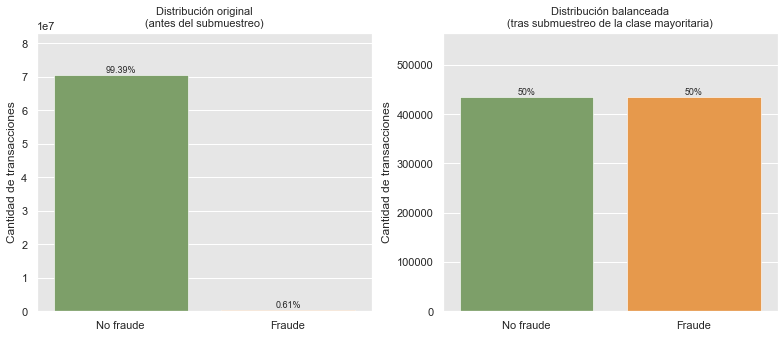

Original  → No fraude: 70,529,018 (99.39%) | Fraude: 435,091 (0.61%)
Balanceado → ambas clases: 435,091


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Datos reales del desbalance ---
counts = transactions_all["TX_FRAUD"].value_counts()
n_legitimas = int(counts.get(0, 0))
n_fraude = int(counts.get(1, 0))

prop = transactions_all["TX_FRAUD"].value_counts(normalize=True)
p_legitimas = prop.get(0, 0) * 100
p_fraude = prop.get(1, 0) * 100

# Tras submuestreo: la mayoritaria se iguala a la minoritaria (1:1)
n_legitimas_sub = n_fraude
n_fraude_sub = n_fraude


df_orig = pd.DataFrame({
    "Clase": ["No fraude", "Fraude"],
    "Cantidad": [n_legitimas, n_fraude],
    "Pct": [p_legitimas, p_fraude],
})
df_sub = pd.DataFrame({
    "Clase": ["No fraude", "Fraude"],
    "Cantidad": [n_legitimas_sub, n_fraude_sub],
    "Pct": [50.0, 50.0],
})

palette = {"No fraude": "#7AA860", "Fraude": "#FF9933"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))

# distribución original 
sns.barplot(data=df_orig, x="Clase", y="Cantidad",
            palette=["#7AA860", "#FF9933"], 
            linewidth=0.6, ax=ax1)
ax1.set_title("Distribución original\n(antes del submuestreo)", fontsize=11)
ax1.set_ylabel("Cantidad de transacciones")
ax1.set_xlabel("")
ax1.set_ylim(0, n_legitimas * 1.18)
for i, row in df_orig.iterrows():
    ax1.text(i, row["Cantidad"], f"{row['Pct']:.2f}%",
             ha="center", va="bottom", fontsize=9)

# tras submuestreo 
sns.barplot(data=df_sub, x="Clase", y="Cantidad",
            palette=["#7AA860", "#FF9933"],
            linewidth=0.6, ax=ax2)
ax2.set_title("Distribución balanceada\n(tras submuestreo de la clase mayoritaria)", fontsize=11)
ax2.set_ylabel("Cantidad de transacciones")
ax2.set_xlabel("")
ax2.set_ylim(0, n_fraude_sub * 1.30)
for i, row in df_sub.iterrows():
    ax2.text(i, row["Cantidad"], f"50%",
             ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig("fig7_desbalance_clases.pdf", dpi=300, bbox_inches="tight")
plt.savefig("fig7_desbalance_clases.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Original  → No fraude: {n_legitimas:,} ({p_legitimas:.2f}%) | "
      f"Fraude: {n_fraude:,} ({p_fraude:.2f}%)")
print(f"Balanceado → ambas clases: {n_fraude_sub:,}")

Cliente de ejemplo: 0


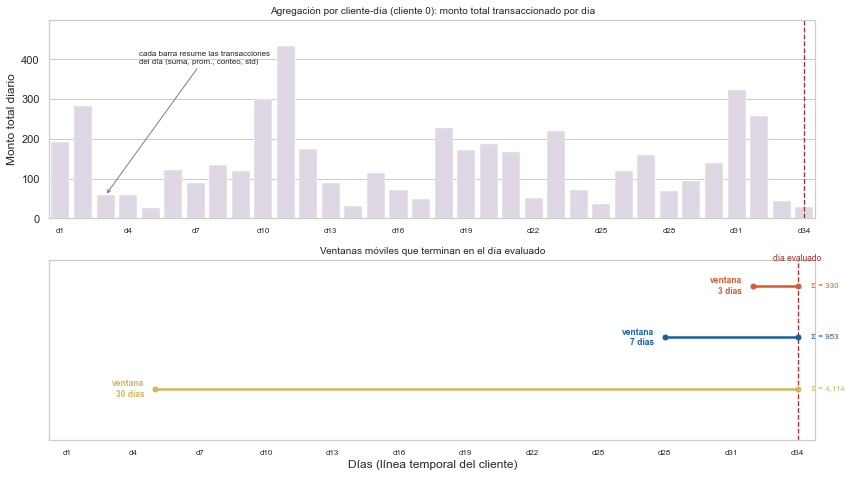

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

sns.set_theme(style="whitegrid", context="notebook")


# PARÁMETROS
DF = transactions_all
COL_CLIENTE = "CUSTOMER_ID"
COL_FECHA   = "TX_DATETIME"
COL_MONTO   = "TX_AMOUNT"

VENTANAS = [3, 7, 30]
N_DIAS_MOSTRAR = 34

C_BAR = "#E1D5E7"                       
C_W = {3: "#D85A30", 7: "#185FA5", 30: "#D6B656"}


# ELEGIR UN CLIENTE CON ACTIVIDAD SUFICIENTE

DF = DF.copy()
DF[COL_FECHA] = pd.to_datetime(DF[COL_FECHA])
DF["FECHA"] = DF[COL_FECHA].dt.floor("D")

dias_por_cliente = DF.groupby(COL_CLIENTE)["FECHA"].nunique()
cliente = dias_por_cliente[dias_por_cliente >= N_DIAS_MOSTRAR + 2].index[0]
print(f"Cliente de ejemplo: {cliente}")

sub = DF[DF[COL_CLIENTE] == cliente].copy()


# AGREGACIÓN POR CLIENTE-DÍA

diario = (sub.groupby("FECHA")
             .agg(monto_total=(COL_MONTO, "sum"),
                  monto_prom=(COL_MONTO, "mean"),
                  n_tx=(COL_MONTO, "count"),
                  monto_std=(COL_MONTO, "std"))
             .reset_index()
             .sort_values("FECHA"))

rango = pd.date_range(diario["FECHA"].min(), diario["FECHA"].max(), freq="D")
diario = (diario.set_index("FECHA").reindex(rango)
                .rename_axis("FECHA").reset_index())
diario[["monto_total", "n_tx"]] = diario[["monto_total", "n_tx"]].fillna(0)
diario = diario.head(N_DIAS_MOSTRAR).reset_index(drop=True)
diario["dia"] = np.arange(N_DIAS_MOSTRAR)


# FEATURES DE VENTANA MÓVIL

for w in VENTANAS:
    diario[f"roll_{w}"] = diario["monto_total"].rolling(window=w, min_periods=1).sum()


# FIGURA DE DOS NIVELES

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(12, 7), gridspec_kw={"height_ratios": [1.1, 1]}, sharex=False)

dias = np.arange(N_DIAS_MOSTRAR)
dia_eval = N_DIAS_MOSTRAR - 1

# agregación cliente-día
sns.barplot(data=diario, x="dia", y="monto_total",
            color=C_BAR, linewidth=0.4, ax=ax_top)
ax_top.set_title(f"Agregación por cliente-día (cliente {cliente}): "
                 "monto total transaccionado por día", fontsize=10)
ax_top.set_ylabel("Monto total diario")
ax_top.set_xlabel("")
ax_top.set_xticks(dias[::3])
ax_top.set_xticklabels([f"d{j+1}" for j in dias[::3]], fontsize=8)
ax_top.margins(y=0.15)


ax_top.annotate("cada barra resume las transacciones\ndel día (suma, prom., conteo, std)",
                xy=(2, diario["monto_total"].iloc[2]),
                xytext=(3.5, ax_top.get_ylim()[1]*0.78),
                fontsize=8, ha="left",
                arrowprops=dict(arrowstyle="->", color="gray", lw=1))

# ventanas deslizantes
ax_bot.set_title("Ventanas móviles que terminan en el día evaluado",
                 fontsize=10)
ax_bot.set_xlim(-0.8, N_DIAS_MOSTRAR - 0.2)
ax_bot.set_ylim(0, len(VENTANAS) + 0.5)
ax_bot.set_yticks([])
ax_bot.set_xticks(dias[::3])
ax_bot.set_xticklabels([f"d{j+1}" for j in dias[::3]], fontsize=8)
ax_bot.grid(False)


for k, w in enumerate(VENTANAS):
    y = len(VENTANAS) - k
    x0 = dia_eval - w + 1
    # línea horizontal que abarca la ventana
    ax_bot.plot([x0, dia_eval], [y, y], color=C_W[w], linewidth=2.5,
                solid_capstyle="round", zorder=2)
    # marcadores en los extremos (inicio y fin de la ventana)
    ax_bot.plot([x0, dia_eval], [y, y], "o", color=C_W[w],
                markersize=5, zorder=3)
    ax_bot.text(x0 - 0.5, y, f"ventana\n{w} días", ha="right", va="center",
                fontsize=8.5, color=C_W[w], fontweight="bold")
    val = diario[f"roll_{w}"].iloc[dia_eval]
    ax_bot.text(dia_eval + 0.6, y, f"Σ = {val:,.0f}", ha="left", va="center",
                fontsize=8, color=C_W[w])

for ax in (ax_top, ax_bot):
    ax.axvline(dia_eval, color="#A32D2D", linestyle="--", linewidth=1.3, zorder=1)
ax_bot.text(dia_eval, len(VENTANAS) + 0.45, "día evaluado",
            ha="center", va="bottom", fontsize=8.5, color="#A32D2D")
ax_bot.set_xlabel("Días (línea temporal del cliente)")


plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("fig9_ventanas_moviles.pdf", dpi=300, bbox_inches="tight")
plt.savefig("fig9_ventanas_moviles.png", dpi=300, bbox_inches="tight")
plt.show()

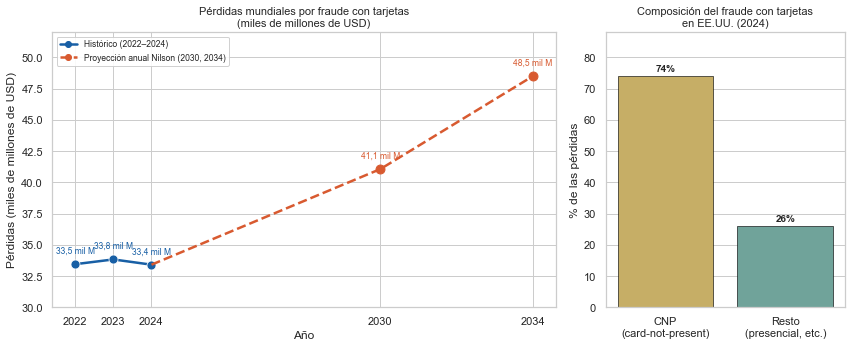

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

sns.set_theme(style="whitegrid", context="notebook")

# DATOS — Nilson Report 

hist = pd.DataFrame({
    "anio": [2022, 2023, 2024],
    "perdidas": [33.45, 33.83, 33.41],
})
proy = pd.DataFrame({
    "anio": [2030, 2034],
    "perdidas": [41.06, 48.50],
})

C_HIST = "#185FA5"   
C_PROY = "#D85A30"   
C_CNP  = "#D6B656"   
C_OTRO = "#67AB9F"   

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5),
                               gridspec_kw={"width_ratios": [2.1, 1]})

# evolución 
sns.lineplot(data=hist, x="anio", y="perdidas", marker="o", markersize=9,
             color=C_HIST, linewidth=2.5, ax=ax1)

# proyección 
puente = pd.DataFrame({"anio": [2024, 2030, 2034],
                       "perdidas": [33.41, 41.06, 48.50]})
ax1.plot(puente["anio"], puente["perdidas"], linestyle="--", color=C_PROY,
         linewidth=2.5, zorder=2)
ax1.scatter(proy["anio"], proy["perdidas"], color=C_PROY, s=80, zorder=3)

# etiquetas de valor sobre cada punto
for _, r in pd.concat([hist, proy]).iterrows():
    es_hist = r["anio"] <= 2024
    ax1.annotate(f"{r['perdidas']:.1f}".replace(".", ",") + " mil M",
                 (r["anio"], r["perdidas"]),
                 textcoords="offset points", xytext=(0, 11),
                 ha="center", fontsize=8.5,
                 color=C_HIST if es_hist else C_PROY)

ax1.set_title("Pérdidas mundiales por fraude con tarjetas\n(miles de millones de USD)",
              fontsize=11)
ax1.set_xlabel("Año")
ax1.set_ylabel("Pérdidas (miles de millones de USD)")
ax1.set_xticks([2022, 2023, 2024, 2030, 2034])
ax1.set_ylim(30, 52)


leyenda = [
    Line2D([0], [0], color=C_HIST, marker="o", linewidth=2.5,
           label="Histórico (2022–2024)"),
    Line2D([0], [0], color=C_PROY, marker="o", linestyle="--", linewidth=2.5,
           label="Proyección anual Nilson (2030, 2034)"),
]
ax1.legend(handles=leyenda, loc="upper left", fontsize=8.5, framealpha=0.9)

# desglose CNP
tipos = ["CNP\n(card-not-present)", "Resto\n(presencial, etc.)"]
valores = [74, 26]
sns.barplot(x=tipos, y=valores, palette=[C_CNP, C_OTRO],
            edgecolor="black", linewidth=0.6, ax=ax2)
ax2.set_title("Composición del fraude con tarjetas\nen EE.UU. (2024)", fontsize=11)
ax2.set_ylabel("% de las pérdidas")
ax2.set_ylim(0, 88)
for i, v in enumerate(valores):
    ax2.text(i, v + 1.5, f"{v}%", ha="center", fontsize=10, fontweight="bold")


plt.tight_layout()
plt.savefig("fig1_magnitud_problema.pdf", dpi=300, bbox_inches="tight")
plt.savefig("fig1_magnitud_problema.png", dpi=300, bbox_inches="tight")
plt.show()

Drifts detectados en transactions_all_run3.parquet (ventana=30): 5
  2018-07-05  caida_relativa=0.27
  2018-09-03  caida_relativa=0.95
  2018-09-09  caida_relativa=0.85
  2019-01-03  caida_relativa=0.38
  2019-01-15  caida_relativa=0.28


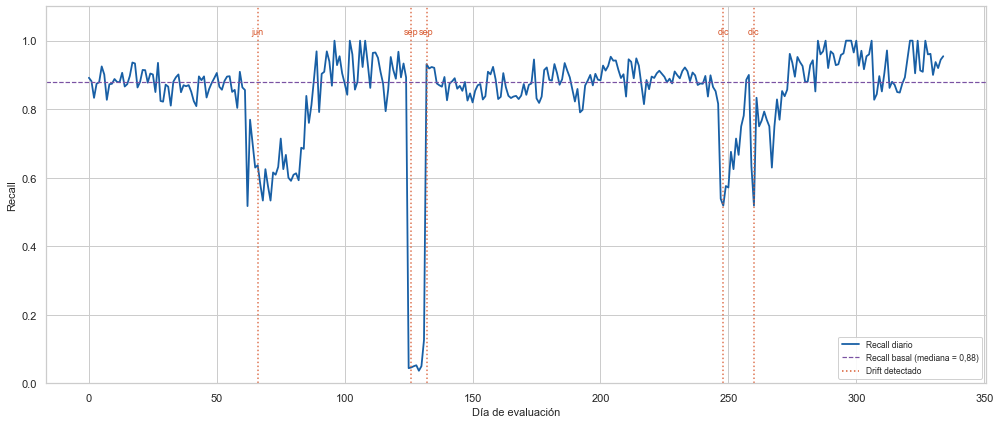

In [ ]:
## Serie temporal de recall con drifts marcados


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from sklearn.metrics import recall_score
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", context="notebook")


# CONFIGURACIÓN

RUTA = '/Users/ceciliaguillametchargue/Tesis/Tesis_MGADO/simulated-data'
archivos = ['transactions_all_run1.parquet', 'transactions_all_run2.parquet','transactions_all_run3.parquet', 'transactions_all_run4.parquet',
            'transactions_all_run5.parquet', 'transactions_all_run6.parquet','transactions_all_run7.parquet', 'transactions_all_run8.parquet',
            'transactions_all_run9.parquet', 'transactions_all_run10.parquet'
            ]

RUN = 'transactions_all_run3.parquet'         
RUN_SEED = 42 + archivos.index(RUN) 
VENTANA = 30

UMBRAL_RELATIVO = 0.25
VENTANA_SUAVIZADO = 3
DIAS_REFRACTARIO = 30


COLOR_RECALL = '#185FA5'     
COLOR_BASELINE = '#7A52A3'    
COLOR_DRIFT = '#D85A30'      

FECHAS_CORTE = {
    'jun': pd.Timestamp('2018-06-30'),
    'sep': pd.Timestamp('2018-09-30'),
    'dic': pd.Timestamp('2018-12-31'),
}


# CARGA Y PREPROCESAMIENTO

df = pd.read_parquet(f'{RUTA}/{RUN}')

le_customer = LabelEncoder()
le_terminal = LabelEncoder()
df['CUSTOMER_ID'] = le_customer.fit_transform(df['CUSTOMER_ID'])
df['TERMINAL_ID'] = le_terminal.fit_transform(df['TERMINAL_ID'])

df['TX_DATETIME'] = pd.to_datetime(df['TX_DATETIME'])
df['TX_TIME'] = df['TX_DATETIME'].dt.hour
df['TX_DAY_WEEK'] = df['TX_DATETIME'].dt.weekday
df['TX_DATETIME'] = df['TX_DATETIME'].dt.normalize()

df = df[df['TX_FRAUD_SCENARIO'] != 1]

FECHA_CORTE_1, FECHA_INICIO_TRANSICION_1 = '2018-06-30', '2018-06-01'
FECHA_CORTE_2, FECHA_INICIO_TRANSICION_2 = '2018-09-30', '2018-09-01'
FECHA_CORTE_3, FECHA_INICIO_TRANSICION_3 = '2018-12-31', '2018-12-01'

condicion_periodo_1 = ((df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_1) &
                        ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
condicion_transicion_1 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_1) & (df['TX_DATETIME'] <= FECHA_CORTE_1) &
                           ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))
condicion_periodo_2 = ((df['TX_DATETIME'] > FECHA_CORTE_1) & (df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_2) &
                        ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))
condicion_transicion_2 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_2) & (df['TX_DATETIME'] <= FECHA_CORTE_2) &
                           ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
condicion_periodo_3 = ((df['TX_DATETIME'] > FECHA_CORTE_2) & (df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_3) &
                        ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
condicion_transicion_3 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_3) & (df['TX_DATETIME'] <= FECHA_CORTE_3) &
                           ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
condicion_periodo_4 = ((df['TX_DATETIME'] > FECHA_CORTE_3) & ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))

df = df[condicion_periodo_1 | condicion_transicion_1 | condicion_periodo_2 |
        condicion_transicion_2 | condicion_periodo_3 | condicion_transicion_3 | condicion_periodo_4]

df = df.sort_values(by=["CUSTOMER_ID", "TX_DATETIME"])
daily_spending = df.groupby(["CUSTOMER_ID", "TX_DATETIME"])["TX_AMOUNT"].agg(
    TX_AMOUNT_DAILY="sum", TX_CNT_DAILY="count"
).reset_index()

for window in [3, 7, 30]:
    daily_spending[f"TX_AMOUNT_{window}D"] = (
        daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
        .rolling(window=window, min_periods=1).sum().reset_index(0, drop=True))
    daily_spending[f"MOV_AVG_TX_AMOUNT_{window}D"] = (
        daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
        .rolling(window=window, min_periods=1).mean().reset_index(0, drop=True))
    daily_spending[f"TX_CNT_{window}D"] = (
        daily_spending.groupby("CUSTOMER_ID")["TX_CNT_DAILY"]
        .rolling(window=window, min_periods=1).sum().reset_index(0, drop=True))
    daily_spending[f"TX_STD_AMOUNT_{window}D"] = (
        daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
        .rolling(window=window, min_periods=1).std().reset_index(0, drop=True))
daily_spending["VAR_TX_AMOUNT_1D"] = daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"].diff()
df = df.merge(daily_spending, on=["CUSTOMER_ID", "TX_DATETIME"], how="left")


# EVALUACIÓN DIARIA + DETECCIÓN DE DRIFT

unique_dates = sorted(df['TX_DATETIME'].unique())
recall_list_eval = []
drifts_detectados = []
en_periodo_refractario = False
dias_desde_drift = 0
baseline_actual = np.nan

for i in range(0, len(unique_dates) - VENTANA):
    contador_inicial, contador_final = i, VENTANA + i
    df_p = df[df['TX_DATETIME'].isin(unique_dates[contador_inicial:contador_final])].copy()
    df_train = df_p[df_p['TX_DATETIME'].isin(unique_dates[contador_inicial:contador_final - 1])]
    df_prueba = df_p[df_p['TX_DATETIME'] == unique_dates[contador_final - 1]]

    try:
        df_ent = df_train[df_train['TX_FRAUD'] == 0].sample(
            n=df_train[df_train['TX_FRAUD'] == 1].shape[0], random_state=RUN_SEED)
    except ValueError:
        continue
    df_ent = pd.concat([df_ent, df_train[df_train['TX_FRAUD'] == 1]])

    features_to_drop = ['TX_DATETIME', 'TX_FRAUD_SCENARIO', 'TX_FRAUD',
                         'TRANSACTION_ID', 'TX_DATE', 'TX_TIME_SECONDS', 'TX_TIME_DAYS']
    columns_to_keep = [c for c in df_ent.columns if c not in features_to_drop]

    X_train, y_train = df_ent[columns_to_keep], df_ent['TX_FRAUD']
    X_test, y_test = df_prueba[columns_to_keep], df_prueba['TX_FRAUD']

    model = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                           objective='binary:logistic', random_state=RUN_SEED, eval_metric='logloss')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    recall_eval = recall_score(y_test, y_pred)
    recall_list_eval.append(recall_eval)

    if en_periodo_refractario:
        dias_desde_drift += 1
        if recall_eval >= baseline_actual or dias_desde_drift >= DIAS_REFRACTARIO:
            en_periodo_refractario = False
            dias_desde_drift = 0

    recall_suavizado = (np.median(recall_list_eval[-VENTANA_SUAVIZADO:])
                         if len(recall_list_eval) >= VENTANA_SUAVIZADO else recall_eval)

    if len(recall_list_eval) > 1 and not en_periodo_refractario:
        baseline_actual = np.median(recall_list_eval[:-1])
        if baseline_actual > 0:
            caida_relativa = (baseline_actual - recall_suavizado) / baseline_actual
            if caida_relativa > UMBRAL_RELATIVO:
                drifts_detectados.append({
                    'fecha': unique_dates[contador_final - 1],
                    'indice_local': len(recall_list_eval) - 1,
                    'caida_relativa': caida_relativa,
                })
                en_periodo_refractario = True
                dias_desde_drift = 0

print(f"Drifts detectados en {RUN} (ventana={VENTANA}): {len(drifts_detectados)}")
for d in drifts_detectados:
    print(f"  {pd.Timestamp(d['fecha']).date()}  caida_relativa={d['caida_relativa']:.2f}")


# ETIQUETADO

def etiqueta_corte(fecha):
    fecha = pd.Timestamp(fecha)
    return min(FECHAS_CORTE.items(), key=lambda kv: abs((fecha - kv[1]).days))[0]

for d in drifts_detectados:
    d['etiqueta'] = etiqueta_corte(d['fecha'])


# Serie temporal de recall con drifts marcados

baseline_recall = float(np.median(recall_list_eval))
xs = list(range(len(recall_list_eval)))

fig, ax = plt.subplots(figsize=(14, 6))

sns.lineplot(x=xs, y=recall_list_eval, color=COLOR_RECALL, linewidth=1.8, ax=ax)
ax.axhline(baseline_recall, color=COLOR_BASELINE, linestyle='--', linewidth=1.2)

for d in drifts_detectados:
    x = d['indice_local']
    ax.axvline(x, color=COLOR_DRIFT, linestyle=':', linewidth=1.5, alpha=0.85)
    ax.annotate(d['etiqueta'], xy=(x, 1.0), xytext=(x, 1.02),
                ha='center', fontsize=9, color=COLOR_DRIFT,
                annotation_clip=False)

ax.set_ylim(0, 1.1)
ax.set_xlabel('Día de evaluación', fontsize=11)
ax.set_ylabel('Recall', fontsize=11)


leyenda = [
    Line2D([0], [0], color=COLOR_RECALL, linewidth=1.8, label='Recall diario'),
    Line2D([0], [0], color=COLOR_BASELINE, linestyle='--', linewidth=1.2,
           label=f"Recall basal (mediana = {baseline_recall:.2f})".replace('.', ',')),
    Line2D([0], [0], color=COLOR_DRIFT, linestyle=':', linewidth=1.5, label='Drift detectado'),
]
ax.legend(handles=leyenda, loc='lower right', fontsize=8.5, framealpha=0.9)


plt.tight_layout()
plt.savefig('fig10_serie_recall.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig10_serie_recall.png', dpi=300, bbox_inches='tight')
plt.show()

No se encontró df_metrics en el kernel: usando valores promedio ya verificados.


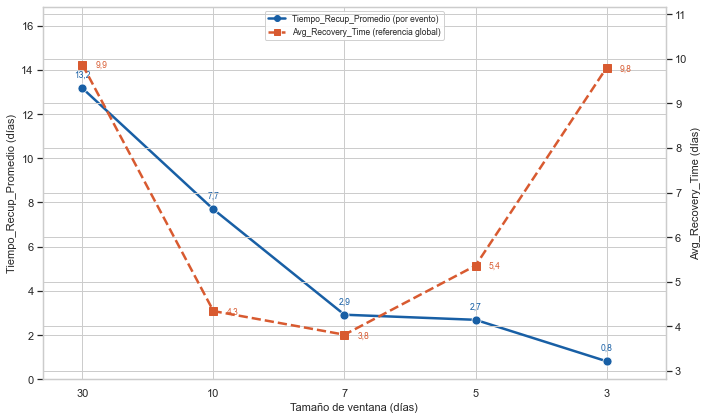

In [ ]:

# Estabilidad vs. plasticidad: tiempo de recuperación según ventana.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

sns.set_theme(style="whitegrid", context="notebook")

COLOR_TIEMPO = '#185FA5'   
COLOR_AVG = '#D85A30'      

VENTANAS = [30, 10, 7, 5, 3]

if 'df_metrics' in globals() and not df_metrics.empty:
    resumen = (
        df_metrics.groupby('ventana')[['Tiempo_Recup_Promedio', 'Avg_Recovery_Time (Days)']]
        .mean()
        .reindex(VENTANAS)
    )
    tiempo_recup = resumen['Tiempo_Recup_Promedio'].tolist()
    avg_recovery = resumen['Avg_Recovery_Time (Days)'].tolist()
    print("Usando df_metrics del kernel.")
else:
    print("No se encontró df_metrics en el kernel: usando valores promedio ya verificados.")
    tiempo_recup = [13.17, 7.69, 2.92, 2.69, 0.815]   
    avg_recovery = [9.87, 4.34, 3.81, 5.36, 9.80]     

datos = pd.DataFrame({
    "ventana": VENTANAS,
    "tiempo_recup": tiempo_recup,
    "avg_recovery": avg_recovery,
})
x = range(len(VENTANAS))

fig, ax1 = plt.subplots(figsize=(10, 6))

sns.lineplot(x=list(x), y=datos["tiempo_recup"], marker="o", markersize=9,
             color=COLOR_TIEMPO, linewidth=2.5, ax=ax1)

ax2 = ax1.twinx()
ax2.plot(x, datos["avg_recovery"], marker="s", markersize=8,
         color=COLOR_AVG, linewidth=2.5, linestyle="--", zorder=3)


ax1.set_ylim(0, max(datos["tiempo_recup"]) * 1.28)
ax2.set_ylim(min(datos["avg_recovery"]) - 1.0, max(datos["avg_recovery"]) + 1.3)

for xi, v in zip(x, datos["tiempo_recup"]):
    ax1.annotate(f"{v:.1f}".replace(".", ","),
                 (xi, v), textcoords="offset points", xytext=(0, 11),
                 ha="center", fontsize=8.5, color=COLOR_TIEMPO)
for xi, v in zip(x, datos["avg_recovery"]):
    ax2.annotate(f"{v:.1f}".replace(".", ","),
                 (xi, v), textcoords="offset points", xytext=(13, -3),
                 ha="left", fontsize=8.5, color=COLOR_AVG)

ax1.set_xlabel("Tamaño de ventana (días)", fontsize=11)
ax1.set_ylabel("Tiempo_Recup_Promedio (días)", fontsize=11)
ax2.set_ylabel("Avg_Recovery_Time (días)", fontsize=11)
ax1.set_xticks(list(x))
ax1.set_xticklabels(VENTANAS)
ax1.set_xlim(-0.3, len(VENTANAS) - 1 + 0.45)


leyenda = [
    Line2D([0], [0], color=COLOR_TIEMPO, marker="o", linewidth=2.5,
           label="Tiempo_Recup_Promedio (por evento)"),
    Line2D([0], [0], color=COLOR_AVG, marker="s", linestyle="--", linewidth=2.5,
           label="Avg_Recovery_Time (referencia global)"),
]
ax1.legend(handles=leyenda, loc="upper center", fontsize=8.5, framealpha=0.9)



plt.tight_layout()
plt.savefig('fig12_estabilidad_plasticidad.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig12_estabilidad_plasticidad.png', dpi=300, bbox_inches='tight')
plt.show()

Reutilizando la simulación ya presente en el kernel (recall_list_eval, drifts_detectados).

Anatomía del evento de septiembre — transactions_all_run3.parquet, ventana=30
  Max_Drop_Magnitude (global, todo el run): 0.843
  Recall_Post_Drift (mediana 5 días, segunda caída): 0.921
  Avg_Recovery_Time (referencia, todo el run): 8.1 días


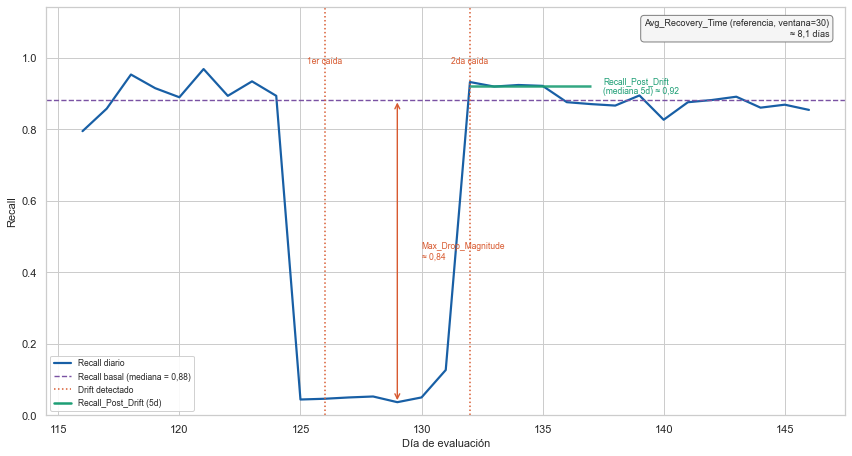

In [ ]:
# Anatomía de una caída (zoom sobre la transición de septiembre).


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from sklearn.metrics import recall_score
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", context="notebook")

COLOR_RECALL = '#185FA5'      
COLOR_BASELINE = '#7A52A3'    
COLOR_DRIFT = '#D85A30'       
COLOR_POST = '#1D9E75'        

RUTA = '/Users/ceciliaguillametchargue/Tesis/Tesis_MGADO/simulated-data'
archivos = ['transactions_all_run1.parquet', 'transactions_all_run2.parquet','transactions_all_run3.parquet', 'transactions_all_run4.parquet',
            'transactions_all_run5.parquet', 'transactions_all_run6.parquet','transactions_all_run7.parquet', 'transactions_all_run8.parquet',
            'transactions_all_run9.parquet', 'transactions_all_run10.parquet'
            ]

RUN = 'transactions_all_run3.parquet'
RUN_SEED = 42 + archivos.index(RUN)
VENTANA = 30
UMBRAL_RELATIVO = 0.25
VENTANA_SUAVIZADO = 3
DIAS_REFRACTARIO = 30
K = 5  

FECHAS_CORTE = {
    'jun': pd.Timestamp('2018-06-30'),
    'sep': pd.Timestamp('2018-09-30'),
    'dic': pd.Timestamp('2018-12-31'),
}


def etiqueta_corte(fecha):
    fecha = pd.Timestamp(fecha)
    return min(FECHAS_CORTE.items(), key=lambda kv: abs((fecha - kv[1]).days))[0]



# DATOS

necesita_simular = not all(v in globals() for v in ['recall_list_eval', 'drifts_detectados', 'unique_dates'])

if necesita_simular:
    print("No se encontró una simulación previa en el kernel: recalculando data-run3 (ventana=30)...")

    df = pd.read_parquet(f'{RUTA}/{RUN}')

    le_customer = LabelEncoder()
    le_terminal = LabelEncoder()
    df['CUSTOMER_ID'] = le_customer.fit_transform(df['CUSTOMER_ID'])
    df['TERMINAL_ID'] = le_terminal.fit_transform(df['TERMINAL_ID'])

    df['TX_DATETIME'] = pd.to_datetime(df['TX_DATETIME'])
    df['TX_TIME'] = df['TX_DATETIME'].dt.hour
    df['TX_DAY_WEEK'] = df['TX_DATETIME'].dt.weekday
    df['TX_DATETIME'] = df['TX_DATETIME'].dt.normalize()

    df = df[df['TX_FRAUD_SCENARIO'] != 1]

    FECHA_CORTE_1, FECHA_INICIO_TRANSICION_1 = '2018-06-30', '2018-06-01'
    FECHA_CORTE_2, FECHA_INICIO_TRANSICION_2 = '2018-09-30', '2018-09-01'
    FECHA_CORTE_3, FECHA_INICIO_TRANSICION_3 = '2018-12-31', '2018-12-01'

    condicion_periodo_1 = ((df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_1) &
                            ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_transicion_1 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_1) & (df['TX_DATETIME'] <= FECHA_CORTE_1) &
                               ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_periodo_2 = ((df['TX_DATETIME'] > FECHA_CORTE_1) & (df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_2) &
                            ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_transicion_2 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_2) & (df['TX_DATETIME'] <= FECHA_CORTE_2) &
                               ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_periodo_3 = ((df['TX_DATETIME'] > FECHA_CORTE_2) & (df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_3) &
                            ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_transicion_3 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_3) & (df['TX_DATETIME'] <= FECHA_CORTE_3) &
                               ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_periodo_4 = ((df['TX_DATETIME'] > FECHA_CORTE_3) & ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))

    df = df[condicion_periodo_1 | condicion_transicion_1 | condicion_periodo_2 |
            condicion_transicion_2 | condicion_periodo_3 | condicion_transicion_3 | condicion_periodo_4]

    df = df.sort_values(by=["CUSTOMER_ID", "TX_DATETIME"])
    daily_spending = df.groupby(["CUSTOMER_ID", "TX_DATETIME"])["TX_AMOUNT"].agg(
        TX_AMOUNT_DAILY="sum", TX_CNT_DAILY="count"
    ).reset_index()

    for window in [3, 7, 30]:
        daily_spending[f"TX_AMOUNT_{window}D"] = (
            daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
            .rolling(window=window, min_periods=1).sum().reset_index(0, drop=True))
        daily_spending[f"MOV_AVG_TX_AMOUNT_{window}D"] = (
            daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
            .rolling(window=window, min_periods=1).mean().reset_index(0, drop=True))
        daily_spending[f"TX_CNT_{window}D"] = (
            daily_spending.groupby("CUSTOMER_ID")["TX_CNT_DAILY"]
            .rolling(window=window, min_periods=1).sum().reset_index(0, drop=True))
        daily_spending[f"TX_STD_AMOUNT_{window}D"] = (
            daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
            .rolling(window=window, min_periods=1).std().reset_index(0, drop=True))
    daily_spending["VAR_TX_AMOUNT_1D"] = daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"].diff()
    df = df.merge(daily_spending, on=["CUSTOMER_ID", "TX_DATETIME"], how="left")

    unique_dates = sorted(df['TX_DATETIME'].unique())
    recall_list_eval = []
    drifts_detectados = []
    en_periodo_refractario = False
    dias_desde_drift = 0
    baseline_actual = np.nan

    for i in range(0, len(unique_dates) - VENTANA):
        contador_inicial, contador_final = i, VENTANA + i
        df_p = df[df['TX_DATETIME'].isin(unique_dates[contador_inicial:contador_final])].copy()
        df_train = df_p[df_p['TX_DATETIME'].isin(unique_dates[contador_inicial:contador_final - 1])]
        df_prueba = df_p[df_p['TX_DATETIME'] == unique_dates[contador_final - 1]]

        try:
            df_ent = df_train[df_train['TX_FRAUD'] == 0].sample(
                n=df_train[df_train['TX_FRAUD'] == 1].shape[0], random_state=RUN_SEED)
        except ValueError:
            continue
        df_ent = pd.concat([df_ent, df_train[df_train['TX_FRAUD'] == 1]])

        features_to_drop = ['TX_DATETIME', 'TX_FRAUD_SCENARIO', 'TX_FRAUD',
                             'TRANSACTION_ID', 'TX_DATE', 'TX_TIME_SECONDS', 'TX_TIME_DAYS']
        columns_to_keep = [c for c in df_ent.columns if c not in features_to_drop]

        X_train, y_train = df_ent[columns_to_keep], df_ent['TX_FRAUD']
        X_test, y_test = df_prueba[columns_to_keep], df_prueba['TX_FRAUD']

        model = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                               objective='binary:logistic', random_state=RUN_SEED, eval_metric='logloss')
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        recall_eval = recall_score(y_test, y_pred)
        recall_list_eval.append(recall_eval)

        if en_periodo_refractario:
            dias_desde_drift += 1
            if recall_eval >= baseline_actual or dias_desde_drift >= DIAS_REFRACTARIO:
                en_periodo_refractario = False
                dias_desde_drift = 0

        recall_suavizado = (np.median(recall_list_eval[-VENTANA_SUAVIZADO:])
                             if len(recall_list_eval) >= VENTANA_SUAVIZADO else recall_eval)

        if len(recall_list_eval) > 1 and not en_periodo_refractario:
            baseline_actual = np.median(recall_list_eval[:-1])
            if baseline_actual > 0:
                caida_relativa = (baseline_actual - recall_suavizado) / baseline_actual
                if caida_relativa > UMBRAL_RELATIVO:
                    if len(recall_list_eval) >= K + 1:
                        recall_pre_drift = recall_list_eval[-K - 1:-1]
                    else:
                        recall_pre_drift = recall_list_eval[:-1]
                    drifts_detectados.append({
                        'fecha': unique_dates[contador_final - 1],
                        'indice_local': len(recall_list_eval) - 1,
                        'baseline_pre_drift': np.median(recall_pre_drift),
                        'caida_relativa': caida_relativa,
                    })
                    en_periodo_refractario = True
                    dias_desde_drift = 0
else:
    print("Reutilizando la simulación ya presente en el kernel (recall_list_eval, drifts_detectados).")

for d in drifts_detectados:
    d['etiqueta'] = etiqueta_corte(d['fecha'])


# MÉTRICAS DE PENALIZACIÓN 

recall_series = pd.Series(recall_list_eval)
baseline_recall = recall_series.median()
drop_threshold = max(0.01, baseline_recall - 0.05)

recovery_times = []
for i in range(len(recall_series)):
    if recall_series.iloc[i] < drop_threshold:
        dias = 0
        recuperado = False
        for j in range(i + 1, len(recall_series)):
            dias += 1
            if recall_series.iloc[j] >= baseline_recall:
                recovery_times.append(dias)
                recuperado = True
                break
        if not recuperado:
            recovery_times.append(np.nan)

avg_recovery_time = np.nanmean(recovery_times) if recovery_times else np.nan

drop_depth_series = baseline_recall - recall_series
significant_drops = drop_depth_series[recall_series < drop_threshold]
max_drop_magnitude = significant_drops.max() if not significant_drops.empty else 0.0

# Recall post-drift 
for d in drifts_detectados:
    start = d['indice_local']
    end = min(start + K, len(recall_list_eval))
    d['recall_post_drift'] = float(np.median(recall_list_eval[start:end]))


# ZOOM EVENTO SEPTIEMBRE

eventos_sep = [d for d in drifts_detectados if d['etiqueta'] == 'sep']
assert eventos_sep, "Esta corrida no detectó ningún evento cerca de septiembre."
primer_hit, segundo_hit = eventos_sep[0], eventos_sep[-1]

margen_pre, margen_post = 10, 15
x_ini = max(0, primer_hit['indice_local'] - margen_pre)
x_fin = min(len(recall_list_eval), segundo_hit['indice_local'] + margen_post)

idx_minimo = int(np.argmin(recall_list_eval[x_ini:x_fin])) + x_ini
recall_minimo = recall_list_eval[idx_minimo]

print(f"\nAnatomía del evento de septiembre — {RUN}, ventana={VENTANA}")
print(f"  Max_Drop_Magnitude (global, todo el run): {max_drop_magnitude:.3f}")
print(f"  Recall_Post_Drift (mediana {K} días, segunda caída): {segundo_hit['recall_post_drift']:.3f}")
print(f"  Avg_Recovery_Time (referencia, todo el run): {avg_recovery_time:.1f} días")


# FIGURA

xs = list(range(x_ini, x_fin))
ys = recall_list_eval[x_ini:x_fin]

fig, ax = plt.subplots(figsize=(12, 6.5))

sns.lineplot(x=xs, y=ys, color=COLOR_RECALL, linewidth=2.2, ax=ax)
ax.axhline(baseline_recall, color=COLOR_BASELINE, linestyle='--', linewidth=1.4)

for d, nombre in [(primer_hit, '1er caída'), (segundo_hit, '2da caída')]:
    ax.axvline(d['indice_local'], color=COLOR_DRIFT, linestyle=':', linewidth=1.5)
    ax.annotate(nombre, xy=(d['indice_local'], max(ys) + 0.015), ha='center',
                fontsize=8.5, color=COLOR_DRIFT, annotation_clip=False)

# Max_Drop_Magnitude: flecha vertical
ax.annotate(
    '', xy=(idx_minimo, recall_minimo), xytext=(idx_minimo, baseline_recall),
    arrowprops=dict(arrowstyle='<->', color=COLOR_DRIFT, lw=1.4)
)
ax.text(idx_minimo + 1, (baseline_recall + recall_minimo) / 2,
        f"Max_Drop_Magnitude\n≈ {max_drop_magnitude:.2f}".replace('.', ','),
        fontsize=8.5, color=COLOR_DRIFT, va='center')

# Recall_Post_Drift: segmento horizontal sobre la ventana K post-segundo hit
post_ini, post_fin = segundo_hit['indice_local'], min(segundo_hit['indice_local'] + K, x_fin - 1)
ax.hlines(segundo_hit['recall_post_drift'], post_ini, post_fin,
          color=COLOR_POST, linewidth=2.5, alpha=0.9)
ax.text(post_fin + 0.5, segundo_hit['recall_post_drift'],
        f"Recall_Post_Drift\n(mediana {K}d) ≈ {segundo_hit['recall_post_drift']:.2f}".replace('.', ','),
        fontsize=8.5, color=COLOR_POST, va='center')

# Avg_Recovery_Time: caja de texto de referencia 
ax.text(0.98, 0.97,
        f"Avg_Recovery_Time (referencia, ventana=30)\n≈ {avg_recovery_time:.1f}".replace('.', ',') + " días",
        transform=ax.transAxes, fontsize=9, ha='right', va='top',
        bbox=dict(boxstyle='round,pad=0.4', fc='whitesmoke', ec='gray'))

ax.set_xlabel('Día de evaluación', fontsize=11)
ax.set_ylabel('Recall', fontsize=11)
ax.set_ylim(0, max(ys) * 1.18)


leyenda = [
    Line2D([0], [0], color=COLOR_RECALL, linewidth=2.2, label='Recall diario'),
    Line2D([0], [0], color=COLOR_BASELINE, linestyle='--', linewidth=1.4,
           label=f"Recall basal (mediana = {baseline_recall:.2f})".replace('.', ',')),
    Line2D([0], [0], color=COLOR_DRIFT, linestyle=':', linewidth=1.5, label='Drift detectado'),
    Line2D([0], [0], color=COLOR_POST, linewidth=2.5, label=f'Recall_Post_Drift ({K}d)'),
]
ax.legend(handles=leyenda, loc='lower left', fontsize=8.5, framealpha=0.9)


plt.tight_layout()
plt.savefig('fig11_anatomia_caida.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig11_anatomia_caida.png', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'test_df' is not defined

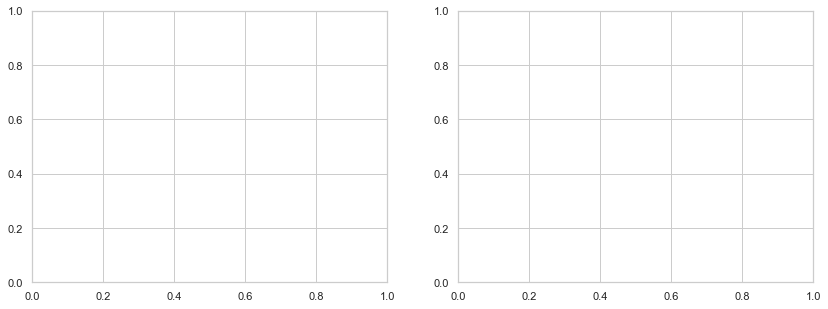

In [ ]:
# Profundidad de la caída vs. velocidad de recuperación.


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

sns.set_theme(style="whitegrid", context="notebook")

COLOR_JUN = '#1D9E75'   
COLOR_SEP = '#D85A30'   
COLOR_DIC = '#7A52A3'   

MARKER_JUN = 'o'
MARKER_SEP = 's'
MARKER_DIC = '^'

FECHAS_CORTE = {
    'jun': pd.Timestamp('2018-06-30'),
    'sep': pd.Timestamp('2018-09-30'),
    'dic': pd.Timestamp('2018-12-31'),
}


def etiqueta_corte(fecha):
    fecha = pd.Timestamp(fecha)
    return min(FECHAS_CORTE.items(), key=lambda kv: abs((fecha - kv[1]).days))[0]



# DATOS

if 'df_metrics' in globals() and not df_metrics.empty and 'Detalle_Drifts' in df_metrics.columns:
    print("Usando df_metrics del kernel (ventana=30).")
    df30 = df_metrics[df_metrics['ventana'] == 30]
    filas = []
    for _, fila in df30.iterrows():
        for d in fila['Detalle_Drifts']:
            filas.append({
                'categoria': etiqueta_corte(d['fecha']),
                'caida': d['caida_relativa'],
                'recuperacion': d['tiempo_recuperacion'],
            })
    eventos = pd.DataFrame(filas)
else:
    print("No se encontró df_metrics en el kernel: usando los 46 eventos ya verificados (ventana=30).")
    
    _EVENTOS_VERIFICADOS = [
        ('jun', 0.3117, 23), ('sep', 0.9385, 6), ('sep', 0.8935, 0), ('dic', 0.3161, 16), ('dic', 0.2672, 0),
        ('jun', 0.3515, 24), ('sep', 0.9364, 9), ('sep', 0.7756, 0), ('dic', 0.3149, 21), ('dic', 0.3008, 1),
        ('jun', 0.3530, 23), ('sep', 0.9427, 60), ('sep', 0.8903, 0), ('dic', 0.2611, 16),
        ('jun', 0.3481, 23), ('jun', 0.2870, 0), ('sep', 0.9496, 8), ('sep', 0.8408, 0), ('dic', 0.2576, 16),
        ('jun', 0.3894, 24), ('sep', 0.9250, 6), ('sep', 0.8504, 0), ('dic', 0.2565, 16), ('dic', 0.2819, 0),
        ('jun', 0.3499, 11), ('jun', 0.2872, 0), ('sep', 0.9375, 13), ('sep', 0.7634, 0), ('dic', 0.3148, 16),
        ('jun', 0.3546, 28), ('sep', 0.9463, 13), ('sep', 0.8028, 0), ('dic', 0.3170, 16),
        ('jun', 0.3494, 24), ('sep', 0.9210, 60), ('sep', 0.8870, 0), ('dic', 0.3166, 16),
        ('jun', 0.3159, 25), ('sep', 0.9390, 7), ('sep', 0.9209, 0), ('dic', 0.3175, 16), ('dic', 0.2851, 0),
        ('jun', 0.3472, 23), ('sep', 0.9407, 7), ('sep', 0.8668, 0), ('dic', 0.2975, 16),
    ]
    eventos = pd.DataFrame(_EVENTOS_VERIFICADOS, columns=['categoria', 'caida', 'recuperacion'])

print(f"Total de eventos: {len(eventos)}  (jun={sum(eventos.categoria == 'jun')}, "
      f"sep={sum(eventos.categoria == 'sep')}, dic={sum(eventos.categoria == 'dic')})")


# FIGURA

COLORES = {'jun': COLOR_JUN, 'sep': COLOR_SEP, 'dic': COLOR_DIC}
MARCADORES = {'jun': MARKER_JUN, 'sep': MARKER_SEP, 'dic': MARKER_DIC}
NOMBRES = {'jun': 'Junio (→ Esc. 3)', 'sep': 'Septiembre (→ Esc. 2, retorno)', 'dic': 'Diciembre (→ Esc. 3)'}

fig, ax = plt.subplots(figsize=(9, 6.5))

rng = np.random.default_rng(7)
for cat in ['jun', 'sep', 'dic']:
    sub = eventos[eventos.categoria == cat]
    jitter_y = rng.normal(0, 0.35, len(sub))  
    ax.scatter(sub['caida'], sub['recuperacion'] + jitter_y,
               color=COLORES[cat], marker=MARCADORES[cat], s=70,
               alpha=0.8, edgecolor='white', linewidth=0.6, zorder=3)

# Medianas por categoría
for cat in ['jun', 'sep', 'dic']:
    sub = eventos[eventos.categoria == cat]
    med_caida, med_recup = sub['caida'].median(), sub['recuperacion'].median()
    ax.scatter([med_caida], [med_recup], color=COLORES[cat], marker=MARCADORES[cat],
               s=260, edgecolor='black', linewidth=1.3, zorder=4)

ax.set_xlabel('Caída relativa de recall', fontsize=11)
ax.set_ylabel('Tiempo de recuperación (días)', fontsize=11)
ax.set_xlim(0.20, 1.0)
ax.set_ylim(-4, eventos['recuperacion'].max() + 8)


leyenda = [
    Line2D([0], [0], marker=MARCADORES[cat], color='w', markerfacecolor=COLORES[cat],
           markeredgecolor='white', markersize=10, label=NOMBRES[cat])
    for cat in ['jun', 'sep', 'dic']
] + [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='none',
           markeredgecolor='black', markeredgewidth=1.3, markersize=13, label='Mediana de la categoría'),
]
ax.legend(handles=leyenda, loc='upper left', bbox_to_anchor=(1.01, 1.0),
          fontsize=8.5, framealpha=0.9, borderaxespad=0)


plt.tight_layout()
plt.savefig('fig13_profundidad_vs_recuperacion.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig13_profundidad_vs_recuperacion.png', dpi=300, bbox_inches='tight')
plt.show()

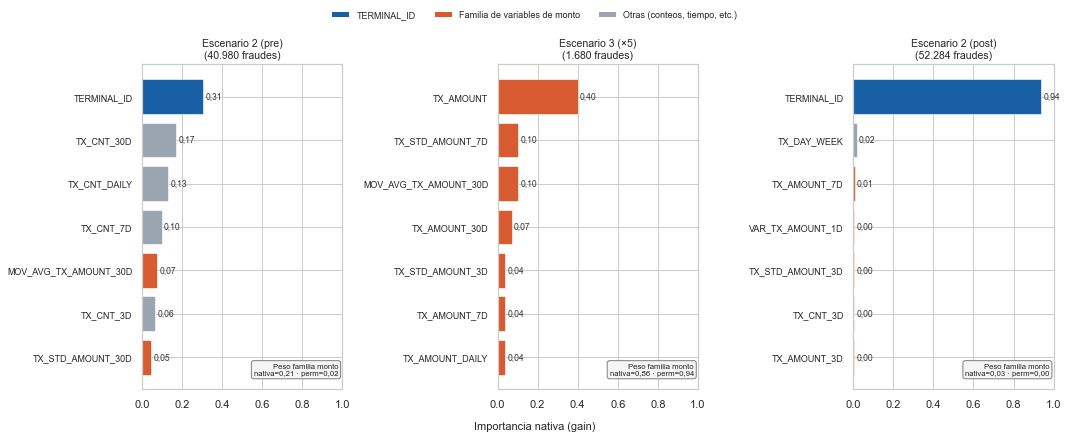

In [ ]:
# Feature importance por régimen de fraude.

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid", context="notebook")

COLOR_TERMINAL = '#185FA5'   
COLOR_MONTO = '#D85A30'      
COLOR_OTRA = '#9AA5B1'       


# DATOS — ranking gain por régimen

REGIMENES = {
    "Escenario 2 (pre)\n(40.980 fraudes)": [
        ("TERMINAL_ID", 0.306, "terminal"),
        ("TX_CNT_30D", 0.169, "otra"),
        ("TX_CNT_DAILY", 0.130, "otra"),
        ("TX_CNT_7D", 0.098, "otra"),
        ("MOV_AVG_TX_AMOUNT_30D", 0.075, "monto"),
        ("TX_CNT_3D", 0.064, "otra"),
        ("TX_STD_AMOUNT_30D", 0.047, "monto")
    ],
    "Escenario 3 (×5)\n(1.680 fraudes)": [
        ("TX_AMOUNT", 0.399, "monto"),
        ("TX_STD_AMOUNT_7D", 0.104, "monto"),
        ("MOV_AVG_TX_AMOUNT_30D", 0.103, "monto"),
        ("TX_AMOUNT_30D", 0.070, "monto"),
        ("TX_STD_AMOUNT_3D", 0.039, "monto"),
        ("TX_AMOUNT_7D", 0.038, "monto"),
        ("TX_AMOUNT_DAILY", 0.038, "monto"),
    ],
    "Escenario 2 (post)\n(52.284 fraudes)": [
        ("TERMINAL_ID", 0.936, "terminal"),
        ("TX_DAY_WEEK", 0.016, "otra"),
        ("TX_AMOUNT_7D", 0.007, "monto"),
        ("VAR_TX_AMOUNT_1D", 0.004, "monto"),
        ("TX_STD_AMOUNT_3D", 0.004, "monto"),
        ("TX_CNT_3D", 0.004, "otra"),
        ("TX_AMOUNT_3D", 0.004, "monto"),
    ],
}

# Peso agregado de la familia monto por régimen
PESO_MONTO = {
    "Escenario 2 (pre)\n(40.980 fraudes)": (0.214, 0.016),
    "Escenario 3 (×5)\n(1.680 fraudes)": (0.86, 0.935),
    "Escenario 2 (post)\n(52.284 fraudes)": (0.032, 0.000),
}

COLORES = {"terminal": COLOR_TERMINAL, "monto": COLOR_MONTO, "otra": COLOR_OTRA}


# FIGURA

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharex=True)

for ax, (regimen, features) in zip(axes, REGIMENES.items()):
    nombres = [f[0] for f in features][::-1]
    valores = [f[1] for f in features][::-1]
    colores = [COLORES[f[2]] for f in features][::-1]

    ax.barh(nombres, valores, color=colores, edgecolor='white', linewidth=0.6)
    for y, v in enumerate(valores):
        ax.text(v + 0.012, y, f"{v:.2f}".replace('.', ','),
                va='center', fontsize=8.5, color='#333333')

    ax.set_title(regimen, fontsize=10.5)
    ax.set_xlim(0, 1.0)
    ax.tick_params(axis='y', labelsize=9)

    nativa, permutacion = PESO_MONTO[regimen]
    ax.text(0.98, 0.04,
            f"Peso familia monto\nnativa={nativa:.2f} · perm={permutacion:.2f}".replace('.', ','),
            transform=ax.transAxes, fontsize=7.8, ha='right', va='bottom',
            bbox=dict(boxstyle='round,pad=0.3', fc='whitesmoke', ec='gray'))

axes[0].set_xlabel("")
fig.text(0.5, -0.02, "Importancia nativa (gain)", ha='center', fontsize=11)

leyenda = [
    Patch(facecolor=COLOR_TERMINAL, label='TERMINAL_ID'),
    Patch(facecolor=COLOR_MONTO, label='Familia de variables de monto'),
    Patch(facecolor=COLOR_OTRA, label='Otras (conteos, tiempo, etc.)'),
]
fig.legend(handles=leyenda, loc='upper center', bbox_to_anchor=(0.5, 1.06),
           ncol=3, fontsize=9, frameon=False)



plt.tight_layout()
plt.savefig('fig14_feature_importance.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig14_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

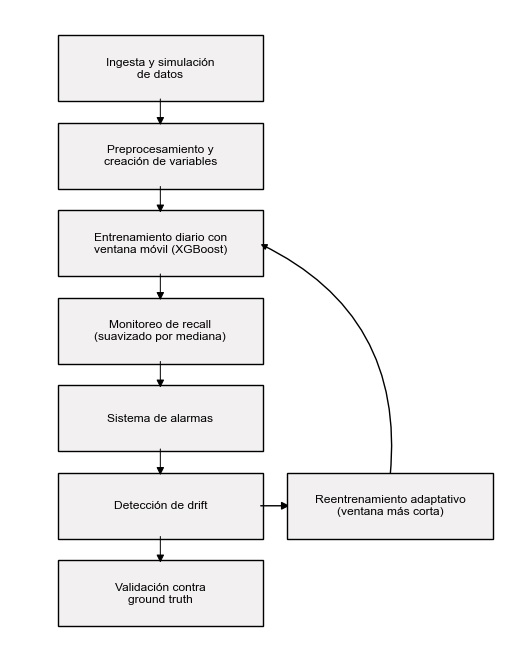

In [ ]:
# Síntesis del pipeline completo.


import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

GRIS = '#000000'      
RELLENO = '#F2F0F0'   

ETAPAS = [
    "Ingesta y simulación\nde datos",
    "Preprocesamiento y\ncreación de variables",
    "Entrenamiento diario con\nventana móvil (XGBoost)",
    "Monitoreo de recall\n(suavizado por mediana)",
    "Sistema de alarmas",
    "Detección de drift",
    "Validación contra\nground truth",
]
ETAPA_ADAPTATIVA = "Reentrenamiento adaptativo\n(ventana más corta)"


# GEOMETRÍA

fig, ax = plt.subplots(figsize=(7.5, 11))

box_w, box_h = 3.6, 1.05
gap = 0.55
x_centro = 0.0
y_top = 0.0

posiciones = []
y = y_top
for _ in ETAPAS:
    posiciones.append(y)
    y -= (box_h + gap)


idx_drift = 5           
idx_entrenamiento = 2   
x_adaptativa = x_centro + box_w / 2 + 2.4
y_adaptativa = posiciones[idx_drift]

for texto, yc in zip(ETAPAS, posiciones):
    box = FancyBboxPatch(
        (x_centro - box_w / 2, yc - box_h / 2), box_w, box_h,
        boxstyle="square,pad=0.08",
        linewidth=1.4, edgecolor=GRIS, facecolor=RELLENO
    )
    ax.add_patch(box)
    ax.text(x_centro, yc, texto, ha='center', va='center',
            fontsize=12, color=GRIS, zorder=4)

# Flechas secuenciales 
for i in range(len(ETAPAS) - 1):
    y_ini = posiciones[i] - box_h / 2
    y_fin = posiciones[i + 1] + box_h / 2
    ax.add_patch(FancyArrowPatch(
        (x_centro, y_ini), (x_centro, y_fin),
        arrowstyle='-|>', mutation_scale=16, linewidth=1,
        color=GRIS, zorder=2,
    ))

# Caja de reentrenamiento adaptativo 
box_ad = FancyBboxPatch(
    (x_adaptativa - box_w / 2, y_adaptativa - box_h / 2), box_w, box_h,
    boxstyle="square,pad=0.08",
    linewidth=1.4, edgecolor=GRIS, facecolor=RELLENO, zorder=3,
)
ax.add_patch(box_ad)
ax.text(x_adaptativa, y_adaptativa, ETAPA_ADAPTATIVA, ha='center', va='center',
        fontsize=12, color=GRIS, zorder=4)

# Flecha: Detección de drift -> Reentrenamiento adaptativo
ax.add_patch(FancyArrowPatch(
    (x_centro + box_w / 2, y_adaptativa), (x_adaptativa - box_w / 2, y_adaptativa),
    arrowstyle='-|>', mutation_scale=16, linewidth=1.4,
    color=GRIS, zorder=2,
))

# Flecha de realimentación
y_entrenamiento = posiciones[idx_entrenamiento]
ax.annotate(
    '', xy=(x_centro + box_w / 2, y_entrenamiento),
    xytext=(x_adaptativa, y_adaptativa + box_h / 2),
    arrowprops=dict(
        arrowstyle='-|>', color=GRIS, linewidth=1.4,
        connectionstyle="arc3,rad=0.35",
    ),
    zorder=2,
)

ax.set_xlim(x_centro - box_w / 2 - 1.0, x_adaptativa + box_w / 2 + 0.6)
ax.set_ylim(posiciones[-1] - box_h / 2 - 0.6, y_top + box_h / 2 + 0.6)
ax.set_aspect('equal')
ax.axis('off')

plt.tight_layout()
plt.savefig('fig15_sintesis_pipeline.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig15_sintesis_pipeline.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Estadísticas descriptivas por variable, comparando las 10 corridas.


import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

sns.set_theme(style="whitegrid", context="notebook")


# CONFIGURACIÓN

RUTA = '/Users/ceciliaguillametchargue/Tesis/Tesis_MGADO/simulated-data'
ARCHIVOS = ['transactions_all_run1.parquet', 'transactions_all_run2.parquet','transactions_all_run3.parquet', 'transactions_all_run4.parquet',
            'transactions_all_run5.parquet', 'transactions_all_run6.parquet','transactions_all_run7.parquet', 'transactions_all_run8.parquet',
            'transactions_all_run9.parquet', 'transactions_all_run10.parquet'
            ]

SAMPLE_SIZE = 300_000     
SAMPLE_SEED = 0

CARPETA_SALIDA = 'figuras_descriptivas'
os.makedirs(CARPETA_SALIDA, exist_ok=True)

COLOR_BOX = '#185FA5'     
PALETA_DISCRETA = ['#1D9E75', '#D85A30', '#7A52A3', '#D6B656', '#67AB9F', '#AB67AA', '#750710']  

VARIABLES_CONTINUAS = [
    'TX_AMOUNT',
    'TX_AMOUNT_DAILY', 'TX_CNT_DAILY',
    'TX_AMOUNT_3D', 'MOV_AVG_TX_AMOUNT_3D', 'TX_CNT_3D', 'TX_STD_AMOUNT_3D',
    'TX_AMOUNT_7D', 'MOV_AVG_TX_AMOUNT_7D', 'TX_CNT_7D', 'TX_STD_AMOUNT_7D',
    'TX_AMOUNT_30D', 'MOV_AVG_TX_AMOUNT_30D', 'TX_CNT_30D', 'TX_STD_AMOUNT_30D',
    'VAR_TX_AMOUNT_1D',
]
VARIABLES_DISCRETAS = ['TX_FRAUD', 'TX_FRAUD_SCENARIO', 'TX_DAY_WEEK']
VARIABLES_DISCRETAS_BARRAS = ['TX_DAY_WEEK']              
VARIABLES_DISCRETAS_LINEA = ['TX_FRAUD', 'TX_FRAUD_SCENARIO'] 
VARIABLE_HORA = 'TX_TIME' 


ETIQUETAS_EJE_Y = {
    'TX_AMOUNT': 'Monto de las transacciones',
    'TX_AMOUNT_DAILY': 'Monto diario de las transacciones',
    'TX_CNT_DAILY': 'Cantidad de transacciones diarias',
    'TX_AMOUNT_3D': 'Suma móvil del monto de las transacciones',
    'TX_AMOUNT_7D': 'Suma móvil del monto de las transacciones',
    'TX_AMOUNT_30D': 'Suma móvil del monto de las transacciones',
    'MOV_AVG_TX_AMOUNT_3D': 'Promedio móvil del monto de las transacciones',
    'MOV_AVG_TX_AMOUNT_7D': 'Promedio móvil del monto de las transacciones',
    'MOV_AVG_TX_AMOUNT_30D': 'Promedio móvil del monto de las transacciones',
    'TX_CNT_3D': 'Cantidad móvil de transacciones',
    'TX_CNT_7D': 'Cantidad móvil de transacciones',
    'TX_CNT_30D': 'Cantidad móvil de transacciones',
    'TX_STD_AMOUNT_3D': 'Desvío estándar móvil de las transacciones',
    'TX_STD_AMOUNT_7D': 'Desvío estándar móvil de las transacciones',
    'TX_STD_AMOUNT_30D': 'Desvío estándar móvil de las transacciones',
    'VAR_TX_AMOUNT_1D': 'Variación de los montos de las transacciones',
    'TX_DAY_WEEK': 'Cantidad de transacciones en los días de la semana',
}



# CARGA Y PREPROCESAMIENTO

def cargar_y_procesar(run_name):
    df = pd.read_parquet(f'{RUTA}/{run_name}')

    le_customer = LabelEncoder()
    le_terminal = LabelEncoder()
    df['CUSTOMER_ID'] = le_customer.fit_transform(df['CUSTOMER_ID'])
    df['TERMINAL_ID'] = le_terminal.fit_transform(df['TERMINAL_ID'])

    df['TX_DATETIME'] = pd.to_datetime(df['TX_DATETIME'])
    df['TX_TIME'] = df['TX_DATETIME'].dt.hour
    df['TX_DAY_WEEK'] = df['TX_DATETIME'].dt.weekday
    df['TX_DATETIME'] = df['TX_DATETIME'].dt.normalize()

    df = df[df['TX_FRAUD_SCENARIO'] != 1]

    FECHA_CORTE_1, FECHA_INICIO_TRANSICION_1 = '2018-06-30', '2018-06-01'
    FECHA_CORTE_2, FECHA_INICIO_TRANSICION_2 = '2018-09-30', '2018-09-01'
    FECHA_CORTE_3, FECHA_INICIO_TRANSICION_3 = '2018-12-31', '2018-12-01'

    condicion_periodo_1 = ((df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_1) &
                            ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_transicion_1 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_1) & (df['TX_DATETIME'] <= FECHA_CORTE_1) &
                               ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_periodo_2 = ((df['TX_DATETIME'] > FECHA_CORTE_1) & (df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_2) &
                            ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_transicion_2 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_2) & (df['TX_DATETIME'] <= FECHA_CORTE_2) &
                               ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_periodo_3 = ((df['TX_DATETIME'] > FECHA_CORTE_2) & (df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_3) &
                            ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_transicion_3 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_3) & (df['TX_DATETIME'] <= FECHA_CORTE_3) &
                               ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_periodo_4 = ((df['TX_DATETIME'] > FECHA_CORTE_3) & ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))

    df = df[condicion_periodo_1 | condicion_transicion_1 | condicion_periodo_2 |
            condicion_transicion_2 | condicion_periodo_3 | condicion_transicion_3 | condicion_periodo_4]

    df = df.sort_values(by=["CUSTOMER_ID", "TX_DATETIME"])
    daily_spending = df.groupby(["CUSTOMER_ID", "TX_DATETIME"])["TX_AMOUNT"].agg(
        TX_AMOUNT_DAILY="sum", TX_CNT_DAILY="count"
    ).reset_index()

    for window in [3, 7, 30]:
        daily_spending[f"TX_AMOUNT_{window}D"] = (
            daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
            .rolling(window=window, min_periods=1).sum().reset_index(0, drop=True))
        daily_spending[f"MOV_AVG_TX_AMOUNT_{window}D"] = (
            daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
            .rolling(window=window, min_periods=1).mean().reset_index(0, drop=True))
        daily_spending[f"TX_CNT_{window}D"] = (
            daily_spending.groupby("CUSTOMER_ID")["TX_CNT_DAILY"]
            .rolling(window=window, min_periods=1).sum().reset_index(0, drop=True))
        daily_spending[f"TX_STD_AMOUNT_{window}D"] = (
            daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
            .rolling(window=window, min_periods=1).std().reset_index(0, drop=True))
    daily_spending["VAR_TX_AMOUNT_1D"] = daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"].diff()
    df = df.merge(daily_spending, on=["CUSTOMER_ID", "TX_DATETIME"], how="left")

    return df


# CARGA DE LAS 10 CORRIDAS

frames = []
cardinalidad = []

for i, archivo in enumerate(ARCHIVOS, start=1):
    t0 = time.time()
    df = cargar_y_procesar(archivo)

    cardinalidad.append({
        'run': f'Corrida {i}',
        'n_customers': df['CUSTOMER_ID'].nunique(),
        'n_terminals': df['TERMINAL_ID'].nunique(),
        'n_filas': len(df),
    })

    if SAMPLE_SIZE is not None and len(df) > SAMPLE_SIZE:
        df = df.sample(n=SAMPLE_SIZE, random_state=SAMPLE_SEED)

    df = df[VARIABLES_CONTINUAS + VARIABLES_DISCRETAS + [VARIABLE_HORA]].copy()
    df['run'] = f'Corrida {i}'
    frames.append(df)

    print(f"{archivo}: procesado en {time.time() - t0:.1f}s "
          f"({cardinalidad[-1]['n_filas']:,} filas, muestra usada: {len(df):,})")

df_todas = pd.concat(frames, ignore_index=True)
runs_orden = [f'Corrida {i}' for i in range(1, len(ARCHIVOS) + 1)]

print("\nCardinalidad de CUSTOMER_ID / TERMINAL_ID por corrida (no graficada):")
print(pd.DataFrame(cardinalidad).to_string(index=False))


# BOXPLOTS — VARIABLES CONTINUAS

for var in VARIABLES_CONTINUAS:
    fig, ax = plt.subplots(figsize=(11, 5.5))
    sns.boxplot(data=df_todas, x='run', y=var, order=runs_orden,
                color=COLOR_BOX, fliersize=1.5, linewidth=1.1, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(ETIQUETAS_EJE_Y.get(var, var), fontsize=11)
    ax.tick_params(axis='x', labelrotation=0)
    # ax.set_title(f'Distribución de {var} por corrida', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'{CARPETA_SALIDA}/desc_{var}.pdf', dpi=300, bbox_inches='tight')
    plt.savefig(f'{CARPETA_SALIDA}/desc_{var}.png', dpi=300, bbox_inches='tight')
    plt.close(fig)
    print(f"Boxplot guardado: {var}")


# BARRAS AGRUPADAS — TX_DAY_WEEK 

for var in VARIABLES_DISCRETAS_BARRAS:
    props = (
        df_todas.groupby('run')[var]
        .value_counts(normalize=True)
        .rename('proporcion')
        .reset_index()
    )
    categorias = sorted(props[var].unique())

    fig, ax = plt.subplots(figsize=(12, 5.5))
    ancho = 0.8 / max(len(categorias), 1)
    xs = np.arange(len(runs_orden))

    for j, cat in enumerate(categorias):
        sub = props[props[var] == cat].set_index('run').reindex(runs_orden)['proporcion'].fillna(0)
        ax.bar(xs + j * ancho, sub.values, width=ancho,
               color=PALETA_DISCRETA[j % len(PALETA_DISCRETA)],
               edgecolor='white', linewidth=0.5, label=f'{var}={cat}')

    ax.set_xticks(xs + ancho * (len(categorias) - 1) / 2)
    ax.set_xticklabels(runs_orden, rotation=0)
    ax.set_ylabel(ETIQUETAS_EJE_Y.get(var, "Proporción dentro de la corrida"), fontsize=11)

    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.02, 1, 0.15), mode='expand',
              ncol=len(categorias), fontsize=8.5, framealpha=0.9, borderaxespad=0)
    
    plt.tight_layout()
    plt.savefig(f'{CARPETA_SALIDA}/desc_{var}.pdf', dpi=300, bbox_inches='tight')
    plt.savefig(f'{CARPETA_SALIDA}/desc_{var}.png', dpi=300, bbox_inches='tight')
    plt.close(fig)
    print(f"Barras guardadas: {var}")


# LÍNEAS CON PORCENTAJE — TX_FRAUD y TX_FRAUD_SCENARIO

xs = np.arange(len(runs_orden))


pct_fraude = (
    df_todas.groupby('run')['TX_FRAUD'].mean().reindex(runs_orden) * 100
)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(xs, pct_fraude.values, marker='o', markersize=8,
        color=COLOR_BOX, linewidth=2.2)
for x, v in zip(xs, pct_fraude.values):
    ax.annotate(f"{v:.2f}".replace('.', ','), (x, v),
                textcoords="offset points", xytext=(0, 10),
                ha='center', fontsize=8.5, color=COLOR_BOX)

ax.set_xticks(xs)
ax.set_xticklabels(runs_orden, rotation=0)
ax.set_ylabel("% de transacciones fraudulentas", fontsize=11)
margen = (pct_fraude.max() - pct_fraude.min()) * 0.6 + 0.05
ax.set_ylim(0, 2)

plt.tight_layout()
plt.savefig(f'{CARPETA_SALIDA}/desc_TX_FRAUD.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{CARPETA_SALIDA}/desc_TX_FRAUD.png', dpi=300, bbox_inches='tight')
plt.close(fig)
print("Línea guardada: TX_FRAUD")

# TX_FRAUD_SCENARIO: % de escenario 2 y % de escenario 3 por corrida
props_escenario = (
    df_todas.groupby('run')['TX_FRAUD_SCENARIO']
    .value_counts(normalize=True)
    .rename('proporcion')
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 5.5))
colores_escenario = {2: PALETA_DISCRETA[1], 3: PALETA_DISCRETA[2]}
for escenario in [2, 3]:
    sub = (
        props_escenario[props_escenario['TX_FRAUD_SCENARIO'] == escenario]
        .set_index('run').reindex(runs_orden)['proporcion'].fillna(0) * 100
    )
    color = colores_escenario[escenario]
    ax.plot(xs, sub.values, marker='o', markersize=8, linewidth=2.2,
            color=color, label=f'Escenario {escenario}')
    for x, v in zip(xs, sub.values):
        ax.annotate(f"{v:.2f}".replace('.', ','), (x, v),
                    textcoords="offset points", xytext=(0, 10),
                    ha='center', fontsize=8, color=color)

ax.set_xticks(xs)
ax.set_xticklabels(runs_orden, rotation=0)
ax.set_ylabel("% de transacciones fraudulentas", fontsize=11)
ax.set_ylim(0, 2)
ax.legend(fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig(f'{CARPETA_SALIDA}/desc_TX_FRAUD_SCENARIO.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{CARPETA_SALIDA}/desc_TX_FRAUD_SCENARIO.png', dpi=300, bbox_inches='tight')
plt.close(fig)
print("Línea guardada: TX_FRAUD_SCENARIO")


# LÍNEAS SUPERPUESTAS — TX_TIME 

horas = np.arange(24)
paleta_horas = sns.color_palette("tab10", n_colors=len(runs_orden))

fig, ax = plt.subplots(figsize=(11, 6))
for run, color in zip(runs_orden, paleta_horas):
    sub = df_todas.loc[df_todas['run'] == run, VARIABLE_HORA]
    prop_hora = sub.value_counts(normalize=True).reindex(horas, fill_value=0) * 100
    ax.plot(horas, prop_hora.values, color=color, linewidth=1.6, alpha=0.85, label=run)

ax.set_xlabel("Hora del día", fontsize=11)
ax.set_ylabel("% de transacciones", fontsize=11)
ax.set_xticks(horas)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.02, 1, 0.15), mode='expand',
          ncol=5, fontsize=8, framealpha=0.9, borderaxespad=0)
# ax.set_title('Distribución horaria de transacciones (TX_TIME) por corrida', fontsize=13)
plt.tight_layout()
plt.savefig(f'{CARPETA_SALIDA}/desc_TX_TIME.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{CARPETA_SALIDA}/desc_TX_TIME.png', dpi=300, bbox_inches='tight')
plt.close(fig)
print("Línea guardada: TX_TIME")


# TABLA RESUMEN

resumen_continuas = df_todas.groupby('run')[VARIABLES_CONTINUAS].describe().T
resumen_continuas.to_csv(f'{CARPETA_SALIDA}/resumen_variables_continuas.csv')
print(f"\nTabla resumen de continuas guardada en {CARPETA_SALIDA}/resumen_variables_continuas.csv")

print(f"\nListo. Todas las figuras y la tabla están en la carpeta: {CARPETA_SALIDA}/")

transactions_all_run1.parquet: procesado en 153.8s (56,507,128 filas, muestra usada: 300,000)
transactions_all_run2.parquet: procesado en 137.3s (56,368,383 filas, muestra usada: 300,000)
transactions_all_run3.parquet: procesado en 136.0s (56,168,068 filas, muestra usada: 300,000)
transactions_all_run4.parquet: procesado en 136.2s (56,336,036 filas, muestra usada: 300,000)
transactions_all_run5.parquet: procesado en 137.5s (56,360,440 filas, muestra usada: 300,000)
transactions_all_run6.parquet: procesado en 137.1s (56,418,463 filas, muestra usada: 300,000)
transactions_all_run7.parquet: procesado en 135.2s (56,283,867 filas, muestra usada: 300,000)
transactions_all_run8.parquet: procesado en 139.9s (56,427,540 filas, muestra usada: 300,000)
transactions_all_run9.parquet: procesado en 137.7s (56,448,091 filas, muestra usada: 300,000)
transactions_all_run10.parquet: procesado en 144.0s (56,459,795 filas, muestra usada: 300,000)

Cardinalidad de CUSTOMER_ID / TERMINAL_ID por corrida (no 

In [ ]:
# Distribución horaria de transacciones: fraude vs. no fraude.

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")


# CONFIGURACIÓN

RUTA = '/Users/ceciliaguillametchargue/Tesis/Tesis_MGADO/simulated-data'
ARCHIVOS = ['transactions_all_run1.parquet', 'transactions_all_run2.parquet','transactions_all_run3.parquet', 'transactions_all_run4.parquet',
            'transactions_all_run5.parquet', 'transactions_all_run6.parquet','transactions_all_run7.parquet', 'transactions_all_run8.parquet',
            'transactions_all_run9.parquet', 'transactions_all_run10.parquet'
            ]

CARPETA_SALIDA = 'figuras_descriptivas'
os.makedirs(CARPETA_SALIDA, exist_ok=True)

COLOR_NO_FRAUDE = '#185FA5'  
COLOR_FRAUDE = '#D85A30'     
COLOR_ESC2 = '#D85A30'       
COLOR_ESC3 = '#7A52A3'       



# CARGA Y PREPROCESAMIENTO

def cargar_periodo(run_name):
    df = pd.read_parquet(f'{RUTA}/{run_name}')

    df['TX_DATETIME'] = pd.to_datetime(df['TX_DATETIME'])
    df['TX_TIME'] = df['TX_DATETIME'].dt.hour
    df['TX_DATETIME'] = df['TX_DATETIME'].dt.normalize()

    df = df[df['TX_FRAUD_SCENARIO'] != 1]

    FECHA_CORTE_1, FECHA_INICIO_TRANSICION_1 = '2018-06-30', '2018-06-01'
    FECHA_CORTE_2, FECHA_INICIO_TRANSICION_2 = '2018-09-30', '2018-09-01'
    FECHA_CORTE_3, FECHA_INICIO_TRANSICION_3 = '2018-12-31', '2018-12-01'

    condicion_periodo_1 = ((df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_1) &
                            ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_transicion_1 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_1) & (df['TX_DATETIME'] <= FECHA_CORTE_1) &
                               ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_periodo_2 = ((df['TX_DATETIME'] > FECHA_CORTE_1) & (df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_2) &
                            ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_transicion_2 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_2) & (df['TX_DATETIME'] <= FECHA_CORTE_2) &
                               ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_periodo_3 = ((df['TX_DATETIME'] > FECHA_CORTE_2) & (df['TX_DATETIME'] <= FECHA_INICIO_TRANSICION_3) &
                            ((df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_transicion_3 = ((df['TX_DATETIME'] > FECHA_INICIO_TRANSICION_3) & (df['TX_DATETIME'] <= FECHA_CORTE_3) &
                               ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 2) | (df['TX_FRAUD_SCENARIO'] == 0)))
    condicion_periodo_4 = ((df['TX_DATETIME'] > FECHA_CORTE_3) & ((df['TX_FRAUD_SCENARIO'] == 3) | (df['TX_FRAUD_SCENARIO'] == 0)))

    df = df[condicion_periodo_1 | condicion_transicion_1 | condicion_periodo_2 |
            condicion_transicion_2 | condicion_periodo_3 | condicion_transicion_3 | condicion_periodo_4]

    return df[['TX_TIME', 'TX_FRAUD', 'TX_FRAUD_SCENARIO']].copy()


frames = []
for archivo in ARCHIVOS:
    frames.append(cargar_periodo(archivo))
    print(f"{archivo}: cargado")

df_todas = pd.concat(frames, ignore_index=True)
n_total = len(df_todas)
n_fraude = int(df_todas['TX_FRAUD'].sum())
print(f"\nTotal de transacciones (10 corridas, sin Escenario 1): {n_total:,}")
print(f"Fraude: {n_fraude:,} ({n_fraude / n_total * 100:.2f}%)".replace('.', ','))

horas = np.arange(24)


# GRÁFICO no fraude vs. fraude

no_fraude = df_todas.loc[df_todas['TX_FRAUD'] == 0, 'TX_TIME']
fraude = df_todas.loc[df_todas['TX_FRAUD'] == 1, 'TX_TIME']

prop_no_fraude = no_fraude.value_counts(normalize=True).reindex(horas, fill_value=0) * 100
prop_fraude = fraude.value_counts(normalize=True).reindex(horas, fill_value=0) * 100

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(horas, prop_no_fraude.values, color=COLOR_NO_FRAUDE, linewidth=2.2,
        marker='o', markersize=4.5, label=f'No fraude (n={len(no_fraude):,})')
ax.plot(horas, prop_fraude.values, color=COLOR_FRAUDE, linewidth=2.2,
        marker='o', markersize=4.5, label=f'Fraude (n={len(fraude):,})')

ax.set_xlabel("Hora del día", fontsize=11)
ax.set_ylabel("% de transacciones (dentro de cada grupo)", fontsize=11)
ax.set_xticks(horas)
ax.legend(fontsize=9.5, framealpha=0.9)

plt.tight_layout()
plt.savefig(f'{CARPETA_SALIDA}/horario_fraude_vs_no_fraude.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{CARPETA_SALIDA}/horario_fraude_vs_no_fraude.png', dpi=300, bbox_inches='tight')
plt.close(fig)
print("\nGráfico guardado: horario_fraude_vs_no_fraude")


# GRÁFICO no fraude vs. Escenario 2 vs. Escenario 3

esc2 = df_todas.loc[df_todas['TX_FRAUD_SCENARIO'] == 2, 'TX_TIME']
esc3 = df_todas.loc[df_todas['TX_FRAUD_SCENARIO'] == 3, 'TX_TIME']

prop_esc2 = esc2.value_counts(normalize=True).reindex(horas, fill_value=0) * 100
prop_esc3 = esc3.value_counts(normalize=True).reindex(horas, fill_value=0) * 100

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(horas, prop_no_fraude.values, color=COLOR_NO_FRAUDE, linewidth=2.0,
        marker='o', markersize=4, alpha=0.6, label=f'No fraude (n={len(no_fraude):,})')
ax.plot(horas, prop_esc2.values, color=COLOR_ESC2, linewidth=2.2,
        marker='o', markersize=4.5, label=f'Escenario 2 (n={len(esc2):,})')
ax.plot(horas, prop_esc3.values, color=COLOR_ESC3, linewidth=2.2,
        marker='o', markersize=4.5, label=f'Escenario 3 (n={len(esc3):,})')

ax.set_xlabel("Hora del día", fontsize=11)
ax.set_ylabel("% de transacciones (dentro de cada grupo)", fontsize=11)
ax.set_xticks(horas)
ax.legend(fontsize=9.5, framealpha=0.9)

plt.tight_layout()
plt.savefig(f'{CARPETA_SALIDA}/horario_por_escenario.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{CARPETA_SALIDA}/horario_por_escenario.png', dpi=300, bbox_inches='tight')
plt.close(fig)
print("Gráfico guardado: horario_por_escenario")

transactions_all_run1.parquet: cargado
transactions_all_run2.parquet: cargado
transactions_all_run3.parquet: cargado
transactions_all_run4.parquet: cargado
transactions_all_run5.parquet: cargado
transactions_all_run6.parquet: cargado
transactions_all_run7.parquet: cargado
transactions_all_run8.parquet: cargado
transactions_all_run9.parquet: cargado
transactions_all_run10.parquet: cargado

Total de transacciones (10 corridas, sin Escenario 1): 563,777,811
Fraude: 1,776,844 (0,32%)

Gráfico guardado: horario_fraude_vs_no_fraude
Gráfico guardado: horario_por_escenario

Kolmogorov-Smirnov sobre TX_TIME:
  No fraude vs. fraude:      D=0.0006, p=5.43e-01
  Escenario 2 vs. Escenario 3: D=0.0025, p=8.39e-01
  (D chico y/o p no significativo => las formas no difieren demasiado;
   D grande y p significativo => sí hay una diferencia real de horario.)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from sklearn.metrics import recall_score
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", context="notebook")


# CONFIGURACIÓN

RUTA = '/Users/ceciliaguillametchargue/Tesis/Tesis_MGADO/simulated-data'
archivos = ['transactions_all_run1.parquet'
#, 'transactions_all_run2.parquet','transactions_all_run3.parquet', 'transactions_all_run4.parquet',
#            'transactions_all_run5.parquet', 'transactions_all_run6.parquet','transactions_all_run7.parquet', 'transactions_all_run8.parquet',
#            'transactions_all_run9.parquet', 'transactions_all_run10.parquet'
            ]

RUN = 'transactions_all_run1.parquet'     
RUN_SEED = 42 + archivos.index(RUN)  
VENTANA = 30

UMBRAL_RELATIVO = 0.25
VENTANA_SUAVIZADO = 3
DIAS_REFRACTARIO = 30


COLOR_RECALL = '#185FA5'      
COLOR_BASELINE = '#7A52A3'    
COLOR_DRIFT = '#D85A30'       

FECHAS_CORTE = {
    'jun': pd.Timestamp('2018-06-30'),
    'sep': pd.Timestamp('2018-09-30'),
    'dic': pd.Timestamp('2018-12-31'),
}


# CARGA Y PREPROCESAMIENTO 

df = pd.read_parquet(f'{RUTA}/{RUN}')

le_customer = LabelEncoder()
le_terminal = LabelEncoder()
df['CUSTOMER_ID'] = le_customer.fit_transform(df['CUSTOMER_ID'])
df['TERMINAL_ID'] = le_terminal.fit_transform(df['TERMINAL_ID'])

df['TX_DATETIME'] = pd.to_datetime(df['TX_DATETIME'])
df['TX_TIME'] = df['TX_DATETIME'].dt.hour
df['TX_DAY_WEEK'] = df['TX_DATETIME'].dt.weekday
df['TX_DATETIME'] = df['TX_DATETIME'].dt.normalize()

df = df[df['TX_FRAUD_SCENARIO'] != 1]

df = df.sort_values(by=["CUSTOMER_ID", "TX_DATETIME"])
daily_spending = df.groupby(["CUSTOMER_ID", "TX_DATETIME"])["TX_AMOUNT"].agg(
    TX_AMOUNT_DAILY="sum", TX_CNT_DAILY="count"
).reset_index()

for window in [3, 7, 30]:
    daily_spending[f"TX_AMOUNT_{window}D"] = (
        daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
        .rolling(window=window, min_periods=1).sum().reset_index(0, drop=True))
    daily_spending[f"MOV_AVG_TX_AMOUNT_{window}D"] = (
        daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
        .rolling(window=window, min_periods=1).mean().reset_index(0, drop=True))
    daily_spending[f"TX_CNT_{window}D"] = (
        daily_spending.groupby("CUSTOMER_ID")["TX_CNT_DAILY"]
        .rolling(window=window, min_periods=1).sum().reset_index(0, drop=True))
    daily_spending[f"TX_STD_AMOUNT_{window}D"] = (
        daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"]
        .rolling(window=window, min_periods=1).std().reset_index(0, drop=True))
daily_spending["VAR_TX_AMOUNT_1D"] = daily_spending.groupby("CUSTOMER_ID")["TX_AMOUNT_DAILY"].diff()
df = df.merge(daily_spending, on=["CUSTOMER_ID", "TX_DATETIME"], how="left")


# EVALUACIÓN DIARIA + DETECCIÓN DE DRIFT

unique_dates = sorted(df['TX_DATETIME'].unique())
recall_list_eval = []
drifts_detectados = []
en_periodo_refractario = False
dias_desde_drift = 0
baseline_actual = np.nan


features_to_drop = ['TX_DATETIME', 'TX_FRAUD_SCENARIO', 'TX_FRAUD',
                         'TRANSACTION_ID', 'TX_DATE', 'TX_TIME_SECONDS', 'TX_TIME_DAYS']
columns_to_keep = [c for c in df.columns if c not in features_to_drop]

In [13]:
descripciones = {'TX_AMOUNT': 'Monto de la transacción',
 'TX_DAY_WEEK': 'Día de la semana',
 'TX_AMOUNT_DAILY': 'Monto diario de las transacciones por cliente',
 'TX_CNT_DAILY': 'Cantidad de transacciones diarias',
 'TX_AMOUNT_3D': 'Suma móvil (3 días) del monto de las transacciones',
 'MOV_AVG_TX_AMOUNT_3D': 'Promedio móvil (3 días) del monto diario de las transacciones',
 'TX_CNT_3D': 'Cantidad móvil (3 días) de las transacciones',
 'TX_STD_AMOUNT_3D': 'Desvío estándar móvil (3 días) del monto diario de las transacciones',
 'TX_AMOUNT_7D': 'Suma móvil (7 días) del monto de las transacciones',
 'MOV_AVG_TX_AMOUNT_7D': 'Promedio móvil (7 días) del monto diario de las transacciones',
 'TX_CNT_7D': 'Cantidad móvil (7 días) de las transacciones',
 'TX_STD_AMOUNT_7D': 'Desvío estándar móvil (7 días) del monto diario de las transacciones',
 'TX_AMOUNT_30D': 'Suma móvil (30 días) del monto de las transacciones',
 'MOV_AVG_TX_AMOUNT_30D': 'Promedio móvil (30 días) del monto diario de las transacciones',
 'TX_CNT_30D': 'Cantidad móvil (30 días) de las transacciones',
 'TX_STD_AMOUNT_30D': 'Desvío estándar móvil (30 días) del monto diario de las transacciones',
 'VAR_TX_AMOUNT_1D': 'Variación del monto de la transacción respecto del día anterior'}

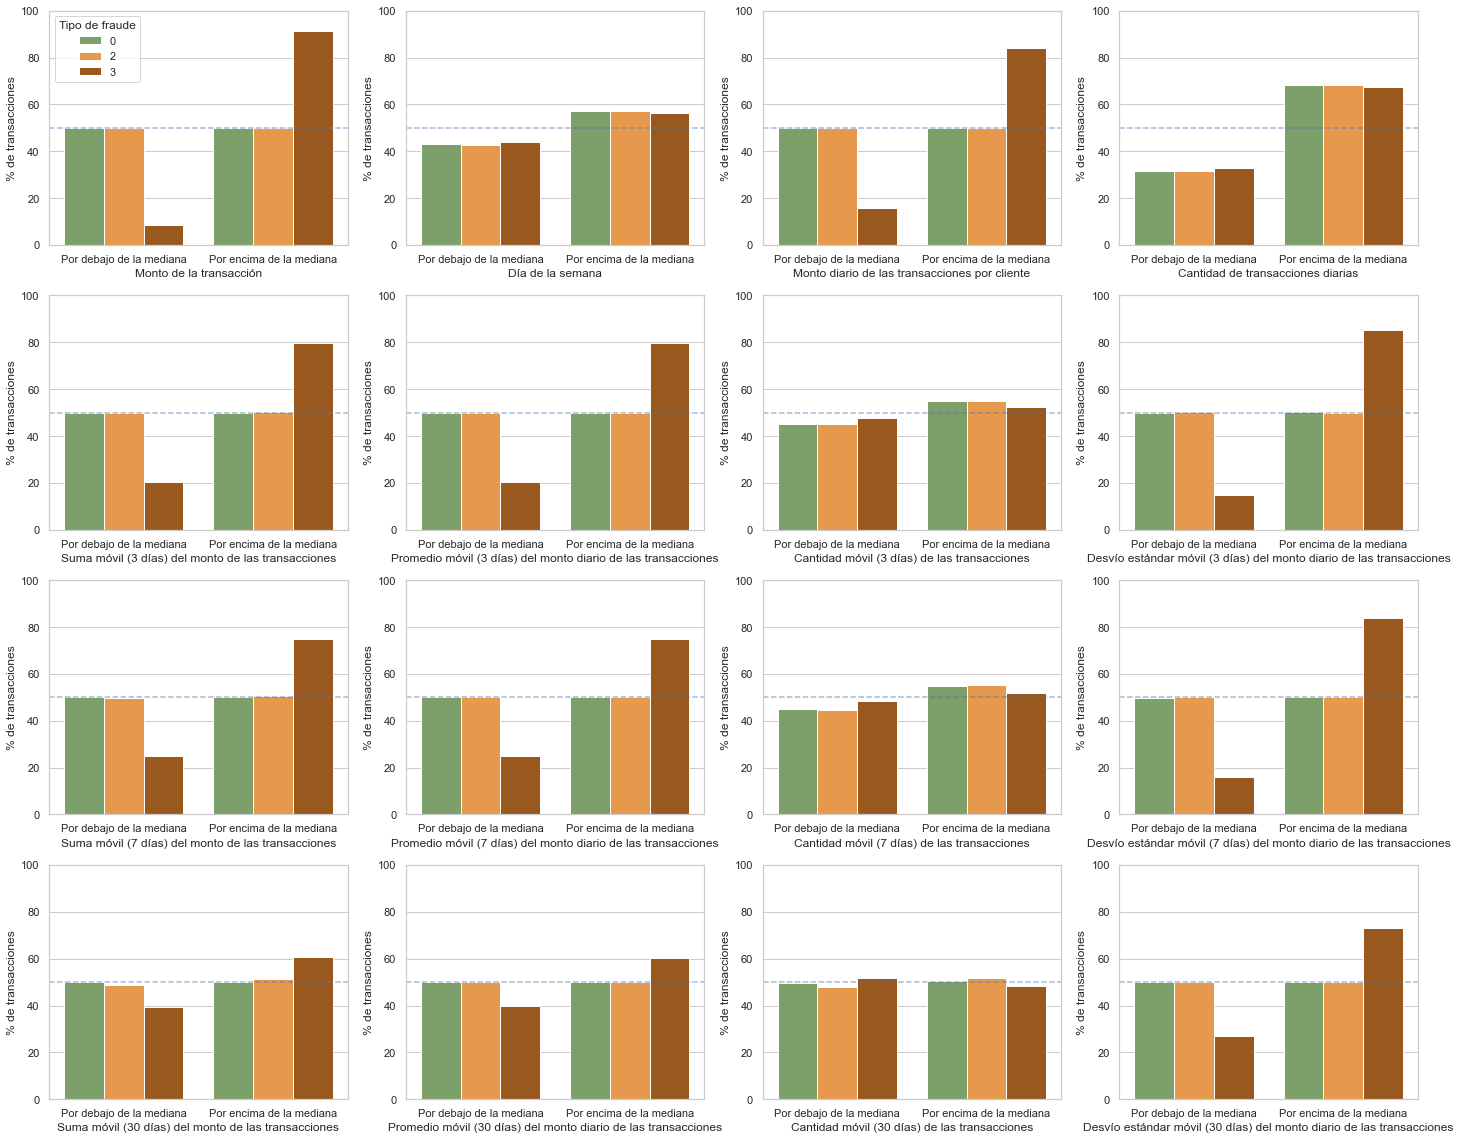

In [ ]:
variables = ['TX_AMOUNT', 'TX_DAY_WEEK', 'TX_AMOUNT_DAILY', 'TX_CNT_DAILY', 'TX_AMOUNT_3D', 'MOV_AVG_TX_AMOUNT_3D',
 'TX_CNT_3D', 'TX_STD_AMOUNT_3D', 'TX_AMOUNT_7D', 'MOV_AVG_TX_AMOUNT_7D', 'TX_CNT_7D', 'TX_STD_AMOUNT_7D', 'TX_AMOUNT_30D',
 'MOV_AVG_TX_AMOUNT_30D', 'TX_CNT_30D', 'TX_STD_AMOUNT_30D', 'VAR_TX_AMOUNT_1D']

palette_scenarios = {
    0: "#7AA860",  
    2: "#FF9933",   
    3: "#AD570A"    
}

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for var, ax in zip(variables, axes):

    median = df[var].median()

    df_temp = df.copy()
    df_temp['median_group'] = np.where(df_temp[var] < median, 'Por debajo de la mediana', 'Por encima de la mediana')
    df_plot = (df_temp.groupby(['TX_FRAUD_SCENARIO', 'median_group']).size().groupby(level=0).transform(lambda x: x / x.sum() * 100).reset_index(name='percentage'))

    sns.barplot(data=df_plot, x='median_group', y='percentage', hue='TX_FRAUD_SCENARIO', palette=palette_scenarios, ax=ax)

    ax.set_ylabel('% de transacciones')
    ax.set_xlabel(descripciones.get(var, var))
    ax.set_ylim(0, 100)
    ax.legend(title= "Tipo de fraude", loc= "upper left")

    ax.axhline(50, linestyle='--', alpha=0.5)

    if ax != axes[0]:
        ax.get_legend().remove()

plt.tight_layout()
plt.savefig('distribucion_variables_por_escenario.pdf', dpi=300, bbox_inches='tight')
plt.savefig('distribucion_variables_por_escenario.png', dpi=300, bbox_inches='tight')
plt.show()